# **Reto Final · Análisis exploratorio de capturas de *Anopheles***

**Curso:** Aprendizaje Estadístico 2026-2  
**Estudiantes:** Jeronimo Lopez Gomez – Jose Daniel Godoy

---

**Pregunta:** ¿Cuántos individuos de *Anopheles* se podrían capturar en una campaña de cuatro noches en Cheté y con qué incertidumbre?

**Referencia inicial (Fermi):** 346 *Anopheles*; escenarios hipotéticos de 122 a 605. Estos valores no son intervalos estadísticos.

## 1. Preparación

Importamos librerías y configuramos las gráficas.

In [155]:
import numpy as np
import pandas as pd
import os
print('Directorio de trabajo:', os.getcwd())

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import contextily as cx #Real Maps Background
import geopandas as gpd
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
import matplotlib as mpl
from matplotlib.patches import Patch


# ------------------------------------------------------------
# PALETA DE COLORES
# ------------------------------------------------------------

COLORES = {
    'principal': '#4472A8',       # Azul
    'secundario': '#C07836',      # Naranja
    'terciario': '#6B8E83',       # Verde grisáceo
    'acento': '#8064A2',          # Violeta
    'negativo': '#B65C5C',        # Rojo suave
    'gris': '#7F8790',
    'gris_claro': '#D9DEE5',
    'fondo': '#FFFFFF',
    'texto': '#303841'
}

# ------------------------------------------------------------
# CONFIGURACIÓN GLOBAL
# ------------------------------------------------------------

mpl.rcParams.update({

    # Figura
    'figure.figsize': (12, 6),
    'figure.dpi': 110,
    'savefig.dpi': 300,
    'figure.facecolor': COLORES['fondo'],
    'axes.facecolor': COLORES['fondo'],

    # Tipografía
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans'],
    'font.size': 10,
    'text.color': COLORES['texto'],

    # Títulos
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlecolor': COLORES['texto'],
    'axes.titlepad': 16,

    # Etiquetas
    'axes.labelsize': 11,
    'axes.labelcolor': COLORES['texto'],

    # Ejes
    'axes.edgecolor': '#BFC5CC',
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,

    # Cuadrícula
    'axes.grid': True,
    'grid.color': '#D9DEE5',
    'grid.linestyle': '--',
    'grid.linewidth': 0.7,
    'grid.alpha': 0.65,

    # Marcas de los ejes
    'xtick.color': COLORES['texto'],
    'ytick.color': COLORES['texto'],
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,

    # Leyendas
    'legend.fontsize': 9,
    'legend.frameon': True,
    'legend.facecolor': 'white',
    'legend.edgecolor': '#D9DEE5',
    'legend.framealpha': 0.95,

    # Líneas
    'lines.linewidth': 2,
    'lines.markersize': 5
})


# ============================================================
# FUNCIÓN PARA FORMATEAR TODAS LAS GRÁFICAS
# ============================================================

def formato_grafica(
    ax,
    titulo=None,
    xlabel=None,
    ylabel=None,
    grid_axis='y'
):

    if titulo:
        ax.set_title(titulo, pad=18, fontweight='bold')

    if xlabel:
        ax.set_xlabel(xlabel, labelpad=9)

    if ylabel:
        ax.set_ylabel(ylabel, labelpad=9)

    ax.grid(
        axis=grid_axis,
        linestyle='--',
        linewidth=0.7,
        alpha=0.55,
        color=COLORES['gris_claro']
    )

    ax.set_axisbelow(True)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.spines['left'].set_color('#BFC5CC')
    ax.spines['bottom'].set_color('#BFC5CC')

    ax.tick_params(
        direction='out',
        length=4,
        width=0.8
    )

    return ax


Directorio de trabajo: c:\Users\Asus\aprendizaje_estadistico\002_EstudiantesAprendizajeEstadistico\semestre2026-2\Estudiantes\Villada_961\reto\ProyectoFinal


## 2. Carga y descripción del conjunto de datos

**Pregunta:** ¿cuántos registros y variables contiene Darwin Core? Revisamos sus primeras filas y la información faltante.


In [156]:
# ============================================================
# 1. CARGA DEL DATASET
# ============================================================

df = pd.read_csv(
    './occurrence.txt',
    sep='\t',
    encoding='utf-8',
    low_memory=False
)

# Solo se analizan Guapi y Timbiquí (Cauca); se descartan los registros
# de Santa Bárbara (Nariño), que no cubren las estaciones IDEAM usadas.
MUNICIPIOS_ESTUDIO = ['Guapi', 'Timbiquí']

n_antes = len(df)
df = df[df['county'].isin(MUNICIPIOS_ESTUDIO)].reset_index(drop=True)

print(f"Registros descartados fuera de {', '.join(MUNICIPIOS_ESTUDIO)}: {n_antes - len(df)}")
print('Registros por municipio:')
print(df['county'].value_counts())
print('-' * 50)


# ============================================================
# 2. INSPECCIÓN GENERAL DEL DATASET
# ============================================================

print("DATASET DE ESPECIES DEL GÉNERO ANOPHELES")
print(f"Dimensiones del dataset: {df.shape[0]} registros × {df.shape[1]} columnas")

display(df.head(5))


# ============================================================
# 3. ANÁLISIS DE ESTRUCTURA Y CALIDAD DE LOS DATOS
# ============================================================

description = pd.DataFrame({
    'Tipo de dato': df.dtypes,
    'Valores no nulos': df.notna().sum(),
    'Valores nulos': df.isna().sum(),
    '% Nulos': (df.isna().mean() * 100).round(2),
    'Valores únicos': df.nunique()
})

print("INFORMACIÓN GENERAL POR COLUMNAS")

display(description.sort_values('% Nulos', ascending=False))

Registros descartados fuera de Guapi, Timbiquí: 125
Registros por municipio:
county
Guapi       780
Timbiquí    597
Name: count, dtype: int64
--------------------------------------------------
DATASET DE ESPECIES DEL GÉNERO ANOPHELES
Dimensiones del dataset: 1377 registros × 68 columnas


,id,type,modified,language,institutionID,institutionCode,datasetName,basisOfRecord,occurrenceID,recordedBy,...,family,genus,subgenus,specificEpithet,taxonRank,scientificNameAuthorship,vernacularName,nomenclaturalCode,taxonomicStatus,taxonRemarks
0,INS:ProyectoVectorLink:Anopheles-1,Event,2022-06-13,es,899.999.403-4,Instituto Nacional de Salud (INS),Instituto Nacional de Salud,HumanObservation,INS:ProyectoVectorLink:Anopheles-1,Manuela Herrera-Varela,...,Culicidae,Anopheles,Nyssorhynchus,albimanus,Especie,"Wiedemann, 1820",Clavito,ICZN,Válido,NaN
1,INS:ProyectoVectorLink:Anopheles-2,Event,2022-06-13,es,899.999.403-4,Instituto Nacional de Salud (INS),Instituto Nacional de Salud,HumanObservation,INS:ProyectoVectorLink:Anopheles-2,Manuela Herrera-Varela,...,Culicidae,Anopheles,Nyssorhynchus,albimanus,Especie,"Wiedemann, 1820",Clavito,ICZN,Válido,NaN
2,INS:ProyectoVectorLink:Anopheles-3,Event,2022-06-13,es,899.999.403-4,Instituto Nacional de Salud (INS),Instituto Nacional de Salud,HumanObservation,INS:ProyectoVectorLink:Anopheles-3,Manuela Herrera-Varela,...,Culicidae,Anopheles,Nyssorhynchus,albimanus,Especie,"Wiedemann, 1820",Clavito,ICZN,Válido,NaN
3,INS:ProyectoVectorLink:Anopheles-4,Event,2022-06-13,es,899.999.403-4,Instituto Nacional de Salud (INS),Instituto Nacional de Salud,HumanObservation,INS:ProyectoVectorLink:Anopheles-4,Manuela Herrera-Varela,...,Culicidae,Anopheles,Nyssorhynchus,albimanus,Especie,"Wiedemann, 1820",Clavito,ICZN,Válido,NaN
4,INS:ProyectoVectorLink:Anopheles-5,Event,2022-06-13,es,899.999.403-4,Instituto Nacional de Salud (INS),Instituto Nacional de Salud,HumanObservation,INS:ProyectoVectorLink:Anopheles-5,Manuela Herrera-Varela,...,Culicidae,Anopheles,Nyssorhynchus,albimanus,Especie,"Wiedemann, 1820",Clavito,ICZN,Válido,NaN


INFORMACIÓN GENERAL POR COLUMNAS


,Tipo de dato,Valores no nulos,Valores nulos,% Nulos,Valores únicos
georeferenceRemarks,object,92,1285,93.32,2
taxonRemarks,object,776,601,43.65,1
verbatimLatitude,object,1285,92,6.68,36
verbatimSRS,object,1285,92,6.68,1
verbatimLongitude,object,1285,92,6.68,36
...,...,...,...,...,...
countryCode,object,1377,0,0.00,1
stateProvince,object,1377,0,0.00,1
county,object,1377,0,0.00,2
municipality,object,1377,0,0.00,2


## 3. Calidad y consistencia

**Pregunta:** ¿hay identificadores repetidos, coordenadas inválidas o fechas incompletas?

In [157]:
# ============================================================
# 4. VALIDACIONES DE INTEGRIDAD DEL DATASET
# ============================================================

print("VALIDACIONES DE INTEGRIDAD")

# Registros completamente duplicados
print("Registros duplicados:", df.duplicated().sum())

# Identificadores de ocurrencia
if 'occurrenceID' in df.columns:
    print("occurrenceID nulos:", df['occurrenceID'].isna().sum())
    print("occurrenceID duplicados:", df['occurrenceID'].duplicated().sum())

# Columnas completamente vacías
empty_columns = df.columns[df.isna().all()].tolist()
print("Columnas completamente vacías:", empty_columns)

# Columnas con un único valor
constant_columns = df.columns[df.nunique() <= 1].tolist()
print("Columnas constantes:", constant_columns)


# ============================================================
# 5. VALIDACIÓN DE COORDENADAS GEOGRÁFICAS
# ============================================================

if {'decimalLatitude', 'decimalLongitude'}.issubset(df.columns):

    latitude = pd.to_numeric(df['decimalLatitude'], errors='coerce')
    longitude = pd.to_numeric(df['decimalLongitude'], errors='coerce')

    valid_coordinates = (
        latitude.between(-90, 90) &
        longitude.between(-180, 180)
    )

    print("VALIDACIÓN GEOGRÁFICA")
    print("Coordenadas faltantes:", (latitude.isna() | longitude.isna()).sum())
    print("Coordenadas fuera de rango:", (~valid_coordinates & latitude.notna() & longitude.notna()).sum())


# ============================================================
# 6. VALIDACIÓN Y PROCESAMIENTO DE FECHAS
# ============================================================

if 'eventDate' in df.columns:

    # Separar fechas iniciales y finales
    date_parts = df['eventDate'].str.split('/', n=1, expand=True)

    dates_start = pd.to_datetime(date_parts[0], errors='coerce')
    dates_end = pd.to_datetime(date_parts[1], errors='coerce')

    # Identificar registros con fecha individual o intervalo
    is_interval = date_parts[1].notna()

    print("VALIDACIÓN TEMPORAL")
    print("Registros con fecha individual:", (~is_interval & dates_start.notna()).sum())
    print("Registros con intervalo de fechas:", (is_interval & dates_start.notna() & dates_end.notna()).sum())
    print("Fechas faltantes o inválidas:", dates_start.isna().sum())

    print("Fecha inicial mínima:", dates_start.min())
    print("Fecha final máxima:", dates_end.fillna(dates_start).max())

VALIDACIONES DE INTEGRIDAD
Registros duplicados: 0
occurrenceID nulos: 0
occurrenceID duplicados: 0
Columnas completamente vacías: []
Columnas constantes: ['type', 'language', 'institutionID', 'institutionCode', 'datasetName', 'basisOfRecord', 'sex', 'lifeStage', 'occurrenceStatus', 'preparations', 'occurrenceRemarks', 'habitat', 'samplingProtocol', 'continent', 'country', 'countryCode', 'stateProvince', 'geodeticDatum', 'verbatimCoordinateSystem', 'verbatimSRS', 'identificationReferences', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'taxonRank', 'vernacularName', 'nomenclaturalCode', 'taxonomicStatus', 'taxonRemarks']
VALIDACIÓN GEOGRÁFICA
Coordenadas faltantes: 92
Coordenadas fuera de rango: 0
VALIDACIÓN TEMPORAL
Registros con fecha individual: 138
Registros con intervalo de fechas: 1221
Fechas faltantes o inválidas: 18
Fecha inicial mínima: 2021-01-02 00:00:00
Fecha final máxima: 2023-03-21 00:00:00


## 4. Cobertura temporal, localidades, esfuerzo y especies

**Preguntas:** ¿cuándo y dónde se hicieron capturas?, ¿qué especies aparecen?, ¿cómo fue el esfuerzo de muestreo?

In [158]:
# ============================================================
# 7. EXPLORACIÓN TEMPORAL DEL DATASET
# ============================================================

# No sobrescribir eventDate: puede contener intervalos inicio/fin.
fecha_evento_inicio = df['eventDate'].astype('string').str.split('/', n=1).str[0]
df['fecha_inicio_registro'] = pd.to_datetime(
    fecha_evento_inicio, errors='coerce', utc=True
)

fecha_inicio = df['fecha_inicio_registro'].min()
fecha_fin = df['fecha_inicio_registro'].max()

print("PERIODO TEMPORAL DE LOS REGISTROS")
print("-" * 50)
print(f"Fecha inicial: {fecha_inicio.strftime('%Y-%m-%d')}")
print(f"Fecha final:   {fecha_fin.strftime('%Y-%m-%d')}")
print(f"Duración:      {(fecha_fin - fecha_inicio).days} días")
print(f"Años cubiertos: {fecha_inicio.year} - {fecha_fin.year}")
print(f"Total de registros: {len(df)}")
print("-" * 50)


# ============================================================
# 8. EXPLORACIÓN DE LOS LUGARES Y HORARIOS DE CAPTURA
# ============================================================

print("Lugares de captura según el hábitat:")
print(df['habitat'].value_counts(dropna=False))
print("--" * 50)

print("\nHorarios o periodos de captura:")
print(df['eventTime'].value_counts(dropna=False))
print("--" * 50)


# ============================================================
# 9. DISTRIBUCIÓN GEOGRÁFICA DE LOS REGISTROS
# ============================================================

print("Clasificación por municipio y localidad:")

locations = (
    df.groupby(['municipality', 'locality'], dropna=False)
      .size()
      .reset_index(name='registros')
      .sort_values('registros', ascending=False)
)

display(locations)


# ============================================================
# 10. EXPLORACIÓN DEL ESFUERZO DE MUESTREO
# ============================================================

print("Descripción del esfuerzo de muestreo:")
print(df['samplingEffort'].value_counts(dropna=False).head(20))
print("--" * 50)

# Extracción de horas y noches
df['horas_noche'] = pd.to_numeric(
    df['samplingEffort'].str.extract(
        r'(?i)(\d+(?:[.,]\d+)?)\s*h(?:oras?)?'
    )[0].str.replace(',', '.', regex=False),
    errors='coerce'
)

df['num_noches'] = pd.to_numeric(
    df['samplingEffort'].str.extract(
        r'(?i)(\d+(?:[.,]\d+)?)\s*noches?'
    )[0].str.replace(',', '.', regex=False),
    errors='coerce'
)

print("\nNúmero de noches por registro:")
print(df['num_noches'].value_counts(dropna=False).sort_index())

print("\nHoras por noche:")
print(df['horas_noche'].value_counts(dropna=False).sort_index())


# ============================================================
# 11. COMPOSICIÓN TAXONÓMICA
# ============================================================

print("Especies de Anopheles registradas:")

species = (
    df['scientificName']
      .value_counts(dropna=False)
      .rename_axis('especie')
      .reset_index(name='registros')
)

species['porcentaje'] = (
    species['registros'] / len(df) * 100
).round(2)

display(species)

PERIODO TEMPORAL DE LOS REGISTROS
--------------------------------------------------
Fecha inicial: 2021-01-02
Fecha final:   2023-03-06
Duración:      793 días
Años cubiertos: 2021 - 2023
Total de registros: 1377
--------------------------------------------------
Lugares de captura según el hábitat:
habitat
En domicilio    1377
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------

Horarios o periodos de captura:
eventTime
17:00:00/05:00:00    1249
17:00:00/07:00:00     128
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
Clasificación por municipio y localidad:


,municipality,locality,registros
7,Guapi,Quiroga,118
4,Guapi,Limones,117
20,Timbiquí,Puerto Saija,98
21,Timbiquí,San Miguel del Río,92
15,Timbiquí,Cheté,77
11,Guapi,Santa Rosa,74
16,Timbiquí,Coteje,62
6,Guapi,Penitente,60
0,Guapi,Chamon,59
14,Timbiquí,Calle del Pueblo,57


Descripción del esfuerzo de muestreo:
samplingEffort
12 h por noche, 4 noches    598
12 h por noche, 3 noches    316
12 h por noche, 5 noches    100
12 h por noche, 1 noche      91
12 h por noche, 2 noches     69
14 h por noche, 2 noches     50
14 h por noche, 1 noche      34
14 h por noche, 3 noches     31
12 h por noche, 3 noche      23
12 h por noche, 6 noches     17
12 h por noche, 4 noche      12
12 h por noche, 2 noche      10
12 h por noche, 1 noches      6
12 h por noche, 6 noche       5
14 h por noche, 4 noches      5
14 h por noche, 6 noches      3
7 h por noche, 4 noches       3
12 h por noche, 5 noche       2
7 h por noche, 6 noches       1
7 h por noche, 2 noches       1
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------

Número de noches por registro:
num_noches
1    131
2    130
3    370
4    618
5    102
6     26
Name: count, dtype: int64

Horas por noche:
horas_noche
7        5
12    1249
14   

,especie,registros,porcentaje
0,Anopheles neivai,775,56.28
1,Anopheles albimanus,457,33.19
2,Anopheles apicimacula,145,10.53


## 5. Distribución geográfica

**Pregunta:** ¿dónde están los registros georreferenciados y cuáles pertenecen a Cheté? Los puntos del mapa representan registros o cantidades según la gráfica, no necesariamente viviendas únicas.

Registros con cantidad de individuos:
Informados: 1285
Sin información: 0


C:\Users\Asus\AppData\Local\Temp\ipykernel_22080\3900051344.py:151: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  punto_chete = gdf_chete.geometry.unary_union.centroid


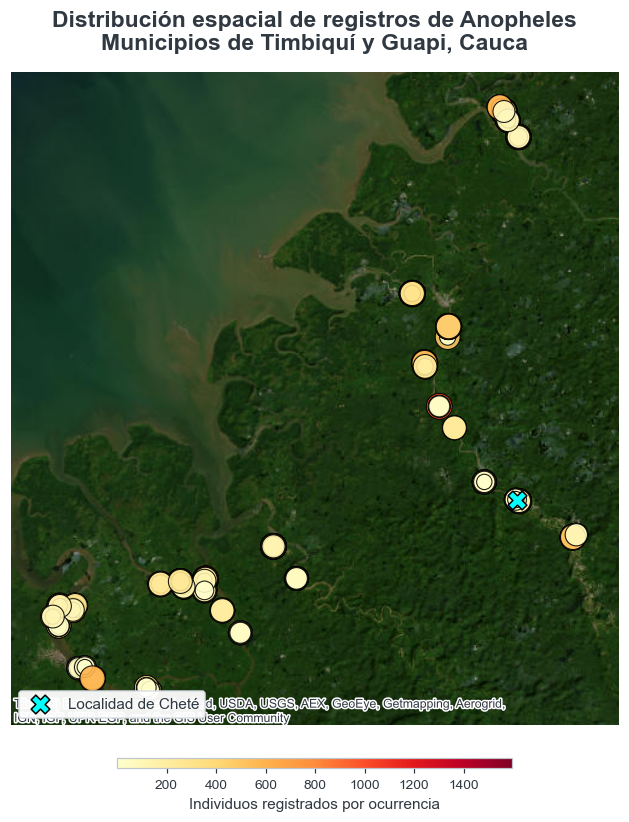

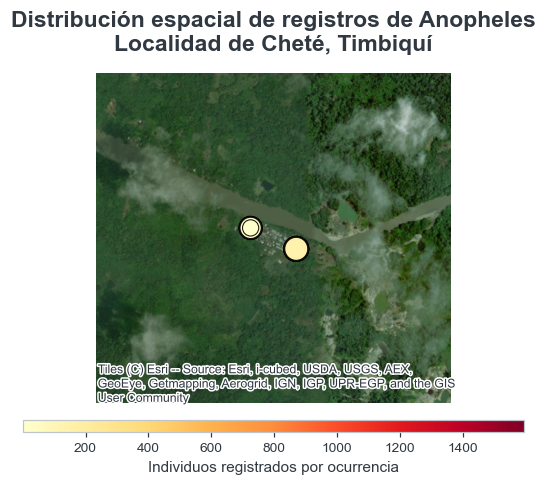


RESUMEN DE DISTRIBUCIÓN GEOGRÁFICA
--------------------------------------------------
Registros cartografiados: 1285
Registros asociados a Cheté: 77
Registros con cantidad informada: 1285
Registros sin cantidad informada: 0


In [159]:
# ============================================================
# 11. DISTRIBUCIÓN GEOGRÁFICA DE ANOPHELES EN TIMBIQUÍ
# ============================================================

# ============================================================
# 11.1. PREPARACIÓN DE LOS DATOS
# ============================================================

# Filtrar registros con coordenadas válidas
df_mapa = df.dropna(
    subset=['decimalLatitude', 'decimalLongitude']
).copy()

df_mapa['decimalLatitude'] = pd.to_numeric(
    df_mapa['decimalLatitude'], errors='coerce'
)

df_mapa['decimalLongitude'] = pd.to_numeric(
    df_mapa['decimalLongitude'], errors='coerce'
)

df_mapa['individualCount'] = pd.to_numeric(
    df_mapa['individualCount'], errors='coerce'
)

df_mapa = df_mapa.dropna(
    subset=['decimalLatitude', 'decimalLongitude']
)

# Filtrar municipio
#df_mapa = df_mapa[
#    df_mapa['municipality'].str.strip().str.casefold() == 'timbiquí'
#].copy()

# Revisar disponibilidad de cantidades
print("Registros con cantidad de individuos:")
print("Informados:", df_mapa['individualCount'].notna().sum())
print("Sin información:", df_mapa['individualCount'].isna().sum())

# Convertir a GeoDataFrame
gdf_mapa = gpd.GeoDataFrame(
    df_mapa,
    geometry=gpd.points_from_xy(
        df_mapa['decimalLongitude'],
        df_mapa['decimalLatitude']
    ),
    crs='EPSG:4326'
).to_crs(epsg=3857)

# Separar registros con y sin cantidad de individuos
gdf_cantidad = gdf_mapa[
    gdf_mapa['individualCount'].notna()
].copy()

gdf_sin_cantidad = gdf_mapa[
    gdf_mapa['individualCount'].isna()
].copy()

# Identificar registros de Cheté
gdf_chete = gdf_mapa[
    gdf_mapa['locality'].str.strip().str.casefold() == 'cheté'
].copy()

gdf_chete_cantidad = gdf_chete[
    gdf_chete['individualCount'].notna()
].copy()

gdf_chete_sin_cantidad = gdf_chete[
    gdf_chete['individualCount'].isna()
].copy()


# ============================================================
# 11.2. ESCALA DE COLOR Y TAMAÑO
# ============================================================

cmap = plt.get_cmap('YlOrRd')

if not gdf_cantidad.empty:

    vmin = gdf_cantidad['individualCount'].min()
    vmax = gdf_cantidad['individualCount'].max()

    norm = Normalize(vmin=vmin, vmax=vmax)

    max_log = np.log1p(
        gdf_cantidad['individualCount'].clip(lower=0)
    ).max()

    def calcular_tamanos(datos):

        valores = np.log1p(
            datos['individualCount'].clip(lower=0)
        )

        if max_log == 0:
            return np.full(len(datos), 100)

        return 80 + 220 * valores / max_log


# ============================================================
# 11.3. MAPA MUNICIPAL DE TIMBIQUÍ
# ============================================================

fig1, ax1 = plt.subplots(
    figsize=(6, 10)
)

# Extensión geográfica del municipio
xmin, ymin, xmax, ymax = gdf_mapa.total_bounds

margin_x = (xmax - xmin) * 0.08
margin_y = (ymax - ymin) * 0.06

ax1.set_xlim(xmin - margin_x, xmax + margin_x)
ax1.set_ylim(ymin - margin_y, ymax + margin_y)

# Registros sin cantidad informada
if not gdf_sin_cantidad.empty:

    gdf_sin_cantidad.plot(
        ax=ax1,
        color='#00BCEB',
        markersize=65,
        alpha=0.9,
        edgecolor='black',
        linewidth=0.6,
        label='Cantidad no informada',
        zorder=3
    )

# Registros con cantidad informada
if not gdf_cantidad.empty:

    gdf_cantidad.plot(
        ax=ax1,
        color=gdf_cantidad['individualCount'].map(
            lambda x: cmap(norm(x))
        ),
        markersize=calcular_tamanos(gdf_cantidad),
        alpha=0.9,
        edgecolor='black',
        linewidth=0.7,
        zorder=4
    )

# Destacar ubicación de Cheté
if not gdf_chete.empty:

    punto_chete = gdf_chete.geometry.unary_union.centroid

    ax1.scatter(
        punto_chete.x,
        punto_chete.y,
        color='cyan',
        marker='X',
        s=150,
        edgecolor='black',
        linewidth=1,
        label='Localidad de Cheté',
        zorder=5
    )

# Mapa base
cx.add_basemap(
    ax1,
    source=cx.providers.Esri.WorldImagery,
    zoom=11
)

ax1.set_title(
    'Distribución espacial de registros de Anopheles\n'
    'Municipios de Timbiquí y Guapi, Cauca',
    fontsize=15,
    fontweight='bold',
    pad=15
)

ax1.legend(
    loc='lower left',
    fontsize=10,
    framealpha=0.95
)

ax1.set_axis_off()

# Barra de color
if not gdf_cantidad.empty:

    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cbar1 = fig1.colorbar(
        sm,
        ax=ax1,
        orientation='horizontal',
        fraction=0.035,
        pad=0.035,
        shrink=0.65,
        aspect=40
    )

    cbar1.set_label(
        'Individuos registrados por ocurrencia',
        fontsize=10
    )

    cbar1.ax.tick_params(labelsize=9)

fig1.subplots_adjust(
    left=0.04,
    right=0.96,
    top=0.94,
    bottom=0.08
)

plt.show()


# ============================================================
# 11.4. DETALLE DE LA LOCALIDAD DE CHETÉ
# ============================================================

if not gdf_chete.empty:

    fig2, ax2 = plt.subplots(
        figsize=(9, 4)
    )

    # Extensión geográfica de Cheté
    xmin, ymin, xmax, ymax = gdf_chete.total_bounds

    margin_x = max((xmax - xmin) * 0.65, 700)
    margin_y = max((ymax - ymin) * 0.65, 700)

    ax2.set_xlim(
        xmin - margin_x,
        xmax + margin_x
    )

    ax2.set_ylim(
        ymin - margin_y,
        ymax + margin_y
    )

    # Registros sin cantidad informada
    if not gdf_chete_sin_cantidad.empty:

        gdf_chete_sin_cantidad.plot(
            ax=ax2,
            color='#00BCEB',
            markersize=65,
            alpha=0.9,
            edgecolor='black',
            linewidth=0.6,
            label='Cantidad no informada',
            zorder=3
        )

    # Registros con cantidad informada
    if not gdf_chete_cantidad.empty:

        gdf_chete_cantidad.plot(
            ax=ax2,
            color=gdf_chete_cantidad['individualCount'].map(
                lambda x: cmap(norm(x))
            ),
            markersize=calcular_tamanos(gdf_chete_cantidad),
            alpha=0.9,
            edgecolor='black',
            linewidth=0.7,
            zorder=4
        )

    # Mapa base
    cx.add_basemap(
        ax2,
        source=cx.providers.Esri.WorldImagery,
        zoom=16
    )

    ax2.set_title(
        'Distribución espacial de registros de Anopheles\n'
        'Localidad de Cheté, Timbiquí',
        fontsize=15,
        fontweight='bold',
        pad=15
    )

    if not gdf_chete_sin_cantidad.empty:

        ax2.legend(
            loc='lower left',
            fontsize=10,
            framealpha=0.95
        )

    ax2.set_axis_off()

    # Barra de color
    if not gdf_cantidad.empty:

        sm = ScalarMappable(norm=norm, cmap=cmap)
        sm.set_array([])

        cbar2 = fig2.colorbar(
            sm,
            ax=ax2,
            orientation='horizontal',
            fraction=0.04,
            pad=0.045,
            shrink=0.55,
            aspect=40
        )

        cbar2.set_label(
            'Individuos registrados por ocurrencia',
            fontsize=10
        )

        cbar2.ax.tick_params(labelsize=9)

    fig2.subplots_adjust(
        left=0.04,
        right=0.96,
        top=0.92,
        bottom=0.10
    )

    plt.show()

else:

    print("No hay registros georreferenciados asociados a Cheté.")


# ============================================================
# 11.5. RESUMEN
# ============================================================

print("\nRESUMEN DE DISTRIBUCIÓN GEOGRÁFICA")
print("-" * 50)

print("Registros cartografiados:", len(gdf_mapa))
print("Registros asociados a Cheté:", len(gdf_chete))
print("Registros con cantidad informada:", len(gdf_cantidad))
print("Registros sin cantidad informada:", len(gdf_sin_cantidad))

## 6. Datos pluviométricos IDEAM

**Pregunta:** ¿qué estaciones, periodos y unidades tenemos disponibles? Revisamos cobertura y registros repetidos. Se cargan el archivo mensual (`dhime_mensual.csv`) y el diario (`dhime_diario.csv`); el diario se usa en las secciones 10 y 11.

In [160]:
# ============================================================
# 12.  DATOS PLUVIOMÉTRICOS DEL IDEAM
# ============================================================

lluvia = pd.read_csv(
    './dhime_mensual.csv',
    sep=',',
    encoding='utf-8',
    low_memory=False,
    parse_dates=['Fecha']
)
# ============================================================
# 12.1. IDENTIFICACIÓN DE ESTACIONES Y VARIABLES
# ============================================================

print("ESTACIONES METEOROLÓGICAS")
print("-" * 60)

estaciones = (
    lluvia.groupby(
        ['CodigoEstacion', 'NombreEstacion'],
        dropna=False
    )
    .agg(
        registros=('Valor', 'count'),
        fecha_inicial=('Fecha', 'min'),
        fecha_final=('Fecha', 'max'),
        precipitacion_maxima=('Valor', 'max')
    )
    .reset_index()
    .sort_values('registros', ascending=False)
)

display(estaciones)

print("\nVARIABLES REGISTRADAS")
print(lluvia['Variable'].value_counts(dropna=False))

print("\nPARÁMETROS REGISTRADOS")
print(lluvia['Parametro'].value_counts(dropna=False))

print("\nUNIDADES DE MEDIDA")
print(lluvia['Unidad'].value_counts(dropna=False))

print("\nNIVELES DE APROBACIÓN")
print(lluvia['NivelAprobacion'].value_counts(dropna=False))


# ============================================================
# 12.2. DISTRIBUCIÓN TEMPORAL DE LOS REGISTROS
# ============================================================

lluvia['Año'] = lluvia['Fecha'].dt.year
lluvia['Mes'] = lluvia['Fecha'].dt.month
lluvia['NombreMes'] = lluvia['Fecha'].dt.month_name()

print("\nREGISTROS POR AÑO")
display(
    lluvia['Año'].value_counts().sort_index()
)

print("\nREGISTROS POR MES")
display(
    lluvia['Mes'].value_counts().sort_index()
)


# ============================================================
# 12.3. REVISIÓN DE REGISTROS REPETIDOS
# ============================================================

duplicados = lluvia.duplicated(
    subset=['CodigoEstacion', 'Fecha', 'Variable', 'Parametro'],
    keep=False
)

print("\nREGISTROS REPETIDOS POR ESTACIÓN Y FECHA")
print("Total:", duplicados.sum())

if duplicados.any():
    display(
        lluvia.loc[duplicados].sort_values(
            ['CodigoEstacion', 'Fecha']
        ).head(20)
    )


# ============================================================
# 12.4. PRECIPITACIÓN DIARIA (2021-2023)
# ============================================================
prep_diaria = pd.read_csv(
    './dhime_diario.csv',
    sep=',',
    encoding='utf-8'
)

print("\nPRECIPITACIÓN DIARIA")
print(prep_diaria.groupby('NombreEstacion')['Fecha'].agg(['min', 'max', 'count']))

ESTACIONES METEOROLÓGICAS
------------------------------------------------------------


,CodigoEstacion,NombreEstacion,registros,fecha_inicial,fecha_final,precipitacion_maxima
3,53050020,TIMBIQUI [53050020],306,2000-01-01,2026-08-01,1346.0
0,53040010,BOCAS DE NAPI [53040010],281,2000-01-01,2026-08-01,1794.0
2,53045040,AEROPUERTO GUAPI - AUT [53045040],271,2000-01-01,2026-08-01,1126.4
6,57025020,GORGONA GUAPI AUT [57025020],251,2000-01-01,2026-08-01,1413.5
5,53060020,SAIJA [53060020],230,2000-01-01,2026-08-01,1253.0
4,53060010,BOCAS DE PATÍA [53060010],207,2000-01-01,2026-08-01,1358.0
1,53045010,BONANZA [53045010],79,2000-01-01,2006-08-01,947.9



VARIABLES REGISTRADAS
Variable
PRECIPITACION    1625
Name: count, dtype: int64

PARÁMETROS REGISTRADOS
Parametro
Precipitación total mensual    1625
Name: count, dtype: int64

UNIDADES DE MEDIDA
Unidad
mm    1625
Name: count, dtype: int64

NIVELES DE APROBACIÓN
NivelAprobacion
Preliminar    1351
Definitivo     274
Name: count, dtype: int64

REGISTROS POR AÑO


Año
2000    83
2001    83
2002    82
2003    79
2004    79
2005    84
2006    79
2007    72
2008    71
2009    72
2010    61
2011    59
2012    30
2013    47
2014    55
2015    60
2016    68
2017    56
2018    46
2019    56
2020    48
2021    41
2022    36
2023    41
2024    48
2025    45
2026    44
Name: count, dtype: int64


REGISTROS POR MES


Mes
1     138
2     137
3     138
4     139
5     132
6     135
7     135
8     141
9     130
10    134
11    132
12    134
Name: count, dtype: int64


REGISTROS REPETIDOS POR ESTACIÓN Y FECHA
Total: 0

PRECIPITACIÓN DIARIA
                                                min               max  count
NombreEstacion                                                              
AEROPUERTO GUAPI - AUT [53045040]  2021-01-04 00:00  2023-12-30 00:00    626
BOCAS DE NAPI [53040010]           2021-01-01 00:00  2023-12-31 00:00   1007
SAIJA [53060020]                   2021-03-01 00:00  2023-12-31 00:00    517
TIMBIQUI [53050020]                2021-01-01 00:00  2023-12-31 00:00   1073


## 7. Precipitación mensual

**Pregunta:** ¿cómo cambia la lluvia entre meses y estaciones? Esta comparación es descriptiva, sin atribuir la lluvia de una estación a cada vivienda.

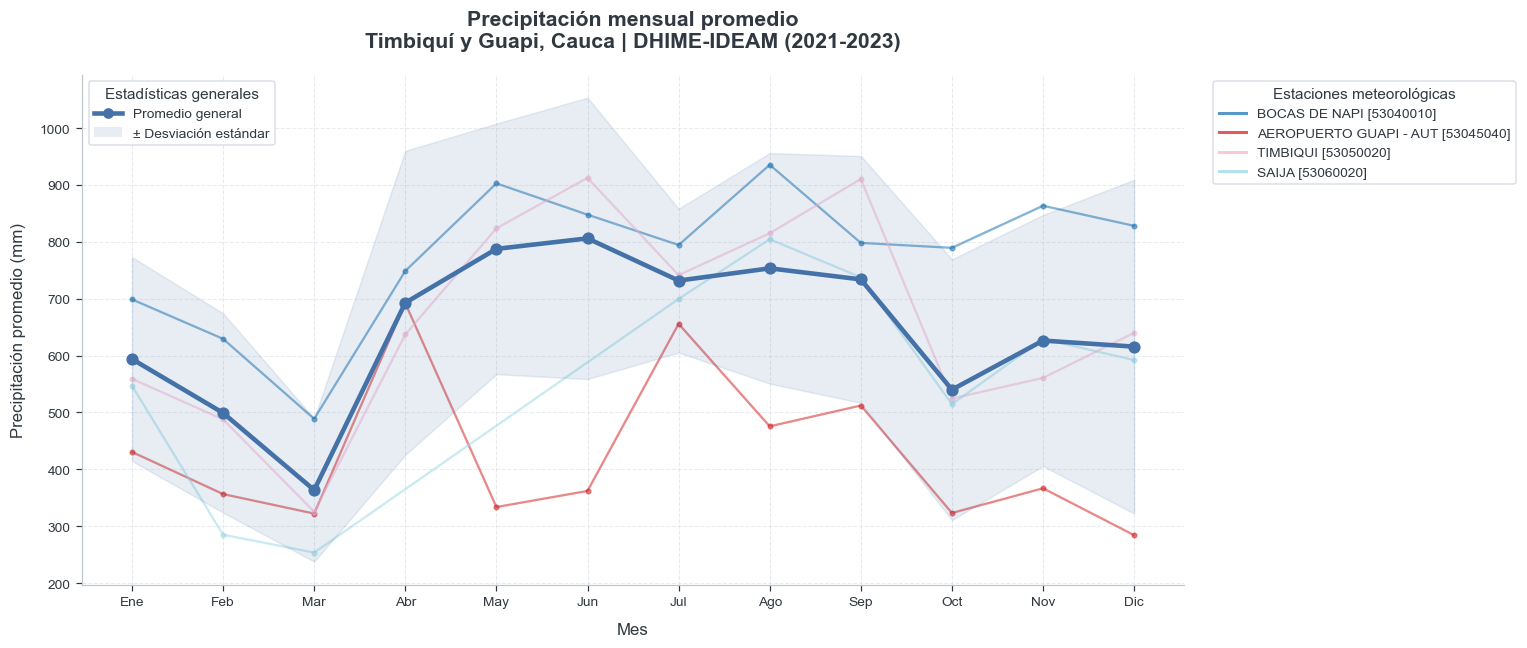

In [161]:
# ============================================================
# 13. PRECIPITACIÓN MENSUAL PROMEDIO POR ESTACIÓN (2021-2023)
# ============================================================

lluvia = lluvia.copy()  # Continuar con el archivo mensual cargado antes

lluvia['Fecha'] = pd.to_datetime(
    lluvia['Fecha'], errors='coerce'
)

lluvia['Valor'] = pd.to_numeric(
    lluvia['Valor'], errors='coerce'
)

lluvia = lluvia.dropna(
    subset=['Fecha', 'Valor', 'CodigoEstacion']
).copy()

lluvia['Año'] = lluvia['Fecha'].dt.year
lluvia['Mes'] = lluvia['Fecha'].dt.month

# Filtrar registros de 2021, 2022 y 2023
# y excluir la estación Gorgona
lluvia = lluvia[
    (lluvia['Año'].isin([2021, 2022, 2023])) &
    (~lluvia['NombreEstacion'].str.contains(
        'Gorgona', case=False, na=False
    ))
].copy()

# Nombres de los meses
meses = [
    'Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
    'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'
]

# ============================================================
# ESTADÍSTICAS MENSUALES POR ESTACIÓN
# ============================================================

stats = (
    lluvia.groupby(
        ['CodigoEstacion', 'NombreEstacion', 'Mes']
    )['Valor']
    .mean()
    .reset_index(name='mean')
)

# ============================================================
# PROMEDIO GENERAL DE TODAS LAS ESTACIONES
# ============================================================

stats_general = (
    lluvia.groupby('Mes')['Valor']
    .agg(['mean', 'std', 'count'])
    .reindex(range(1, 13))
)

# ============================================================
# GRÁFICA
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

# Paleta de colores para las estaciones
estaciones = stats[
    ['CodigoEstacion', 'NombreEstacion']
].drop_duplicates()

colores = plt.cm.tab20(
    np.linspace(0, 1, len(estaciones))
)

# Curvas individuales por estación
for (_, estacion), color in zip(
    estaciones.iterrows(), colores
):

    datos = stats[
        stats['CodigoEstacion'] == estacion['CodigoEstacion']
    ].sort_values('Mes')

    ax.plot(
        datos['Mes'],
        datos['mean'],
        marker='o',
        markersize=3,
        linewidth=1.5,
        color=color,
        alpha=0.55
    )

# Promedio general
ax.plot(
    stats_general.index,
    stats_general['mean'],
    marker='o',
    markersize=7,
    linewidth=3,
    color=COLORES['principal'],
    zorder=10,
    label='Promedio general'
)

# Desviación estándar del promedio general
ax.fill_between(
    stats_general.index,
    stats_general['mean'] - stats_general['std'],
    stats_general['mean'] + stats_general['std'],
    color=COLORES['principal'],
    alpha=0.12,
    zorder=5
)

# ============================================================
# FORMATO
# ============================================================

ax.set_xticks(range(1, 13))
ax.set_xticklabels(meses)

formato_grafica(
    ax,
    titulo='Precipitación mensual promedio\n'
           'Timbiquí y Guapi, Cauca | DHIME-IDEAM (2021-2023)',
    xlabel='Mes',
    ylabel='Precipitación promedio (mm)'
)

# ============================================================
# LEYENDA GENERAL
# ============================================================

handles_general = [
    Line2D(
        [0], [0],
        color=COLORES['principal'],
        linewidth=3,
        marker='o',
        markersize=6,
        label='Promedio general'
    ),
    Patch(
        facecolor=COLORES['principal'],
        alpha=0.12,
        label='± Desviación estándar'
    )
]

legend_general = ax.legend(
    handles=handles_general,
    title='Estadísticas generales',
    loc='upper left'
)

ax.add_artist(legend_general)

# ============================================================
# LEYENDA DE ESTACIONES
# ============================================================

handles_estaciones = [
    Line2D(
        [0], [0],
        color=color,
        linewidth=2,
        alpha=0.75,
        label=estacion['NombreEstacion']
    )
    for (_, estacion), color in zip(
        estaciones.iterrows(), colores
    )
]

ax.legend(
    handles=handles_estaciones,
    title='Estaciones meteorológicas',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

# ============================================================
# AJUSTE FINAL
# ============================================================

plt.tight_layout()
plt.show()

## 8. Medida de captura: *Anopheles* por casa-hora

**Por qué no basta con contar individuos:** las visitas tienen esfuerzos distintos (de 1 a 6 noches, de 12 o 14 h por noche). Una visita de 6 noches captura más que una de 1 noche aunque haya los mismos mosquitos. Para comparar hay que dividir por el esfuerzo.

**Unidad de muestreo:** la **casa** (vivienda con colecta por cebo humano dentro del domicilio). El dataset no informa cuántos colectores había en cada casa, así que el esfuerzo se mide en **casa-horas**.

**Cálculo.** Para una visita $v$ (una casa en una campaña mensual):

$$
N_v = \sum_{\text{especies}} \texttt{individualCount}, \qquad
E_v = \text{noches}_v \times \text{horas por noche}_v \;\;(\text{casa-horas}), \qquad
\text{tasa}_v = \frac{N_v}{E_v}
$$

Las noches y las horas salen de `samplingEffort` ("12 h por noche, 4 noches"). Para varias casas, un mes o una campaña se usa la **razón de sumas** $\sum N_v / \sum E_v$, no el promedio de las tasas: así una visita de 1 noche no pesa lo mismo que una de 6.

**Ejemplo (Cheté, noviembre de 2022):**

| Casa | *An. albimanus* | *An. neivai* | $N_v$ | Esfuerzo | $E_v$ | Tasa |
|---|---:|---:|---:|---|---:|---:|
| Chete1 | 607 | 19 | 626 | 4 noches × 12 h | 48 | 13,0 |
| Chete2 | 89 | 5 | 94 | 4 noches × 12 h | 48 | 2,0 |
| **Campaña** | | | **720** | | **96** | **7,5** |

Se usa escala logaritmica en algunas representaciones dado lo siguiente

1. **La tasa es muy asimétrica y abarca varios órdenes de magnitud** (de centésimas a decenas por casa-hora). En escala lineal, unas pocas visitas altas aplastan al resto y no se ven las diferencias entre las demás. En escala log la distribución es mucho menos asimétrica y se ven todas las visitas.
2. **Los efectos son multiplicativos.**

MEDIDA DE CAPTURA
------------------------------------------------------------
Visitas casa × mes: 829 | campañas localidad × mes: 505
Registros con fechas incoherentes (se usó el mes completo): 33
------------------------------------------------------------

EJEMPLO: CHETÉ, NOVIEMBRE DE 2022


,casa,N,noches,horas,casa_horas,tasa
562,Chete1,626,4.0,12.0,48.0,13.04
584,Chete2,94,4.0,12.0,48.0,1.96


Campaña: 720 / 96 = 7.50 Anopheles por casa-hora

DISTRIBUCIÓN DE LA TASA POR VISITA
------------------------------------------------------------
Mínimo: 0.028 | mediana: 4.06 | máximo: 37.1 (razón máx/mín ≈ 1,337)
Asimetría (skewness) en escala lineal: 1.72
Asimetría en escala log:              -0.84  (0 = simétrica)
------------------------------------------------------------


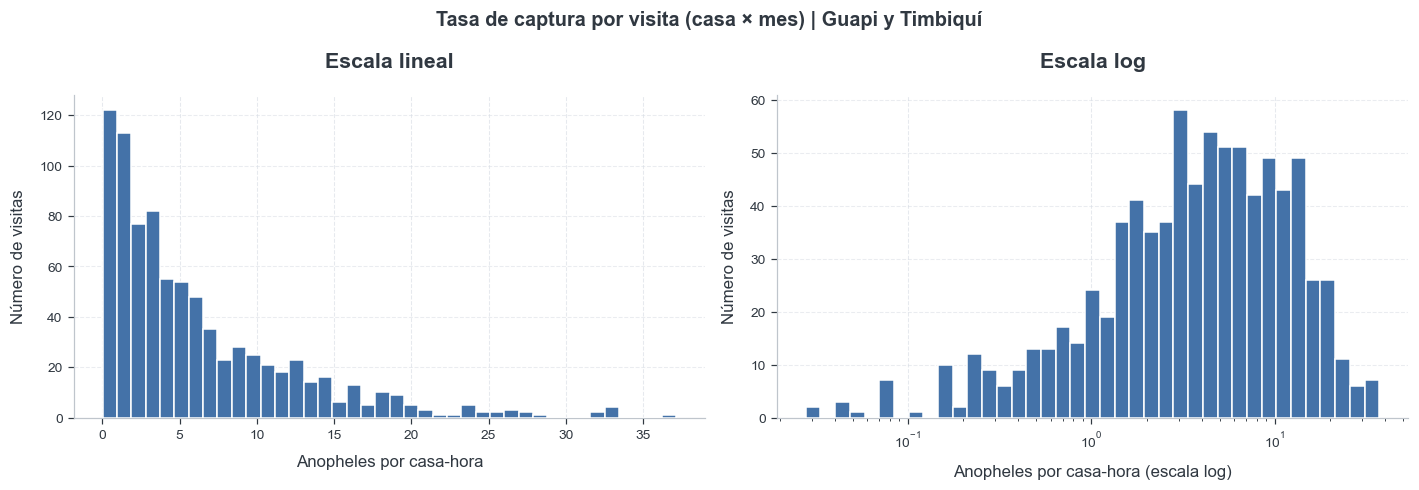

In [162]:
# ============================================================
# 8. MEDIDA DE CAPTURA: VISITAS, CAMPAÑAS Y TASA POR CASA-HORA
# ============================================================
from scipy import stats

# ============================================================
# 8.1. CAMPAÑA (MES), CASA Y ESFUERZO DE CADA REGISTRO
# ============================================================
# El mes de la campaña se toma de verbatimEventDate porque eventDate
# tiene nulos y errores de año.

MESES_ES = {'enero': 1, 'febrero': 2, 'marzo': 3, 'abril': 4, 'mayo': 5, 'junio': 6,
            'julio': 7, 'agosto': 8, 'septiembre': 9, 'octubre': 10,
            'noviembre': 11, 'diciembre': 12}

def campania_desde_verbatim(v):
    v = str(v).strip().lower()
    partes = v.split()
    if len(partes) == 2 and partes[0] in MESES_ES:
        return pd.Period(year=int(partes[1]), month=MESES_ES[partes[0]], freq='M')
    return pd.Period(v.split('/')[0], freq='M')

def casa_desde_ids(row):
    # 'Mataco_01' (sin guion) = casa 'Mataco'; 'Saija_1-01' = casa 'Saija1'.
    if '-' in row['eventID']:
        return row['parentEventID'].replace('_', '')
    return row['eventID'].rsplit('_', 1)[0]

reg = df.copy()
reg['individualCount'] = pd.to_numeric(reg['individualCount'], errors='coerce')
reg['campania'] = reg['verbatimEventDate'].map(campania_desde_verbatim)
reg['casa'] = reg.apply(casa_desde_ids, axis=1)
reg['horas'] = reg['samplingEffort'].str.extract(r'(\d+)\s*h')[0].astype(float)
reg['noches'] = reg['samplingEffort'].str.extract(r'(\d+)\s*noche')[0].astype(float)

# Fechas de inicio y fin de las noches. Solo se aceptan si son coherentes
# con el mes de la campaña; si no, se usa el mes completo.
fechas = reg['eventDate'].astype('string')
reg['inicio'] = pd.to_datetime(fechas.str.split('/').str[0], errors='coerce')
reg['fin'] = pd.to_datetime(fechas.str.split('/').str[-1], errors='coerce')
fecha_ok = (
    (reg['inicio'].dt.to_period('M') == reg['campania'])
    & (reg['fin'] >= reg['inicio'])
    & ((reg['fin'] - reg['inicio']).dt.days <= 45)
)
reg.loc[~fecha_ok, ['inicio', 'fin']] = pd.NaT

# ============================================================
# 8.2. VISITAS (CASA × MES) Y CAMPAÑAS (LOCALIDAD × MES)
# ============================================================
# Las noches pueden diferir entre especies de la misma visita;
# se toma el máximo como esfuerzo de la visita.
visitas = (
    reg.groupby(['county', 'locality', 'casa', 'campania'])
    .agg(N=('individualCount', 'sum'),
         noches=('noches', 'max'),
         horas=('horas', 'max'),
         inicio=('inicio', 'min'),
         fin=('fin', 'max'))
    .reset_index()
)
visitas['casa_horas'] = visitas['noches'] * visitas['horas']
visitas['tasa'] = visitas['N'] / visitas['casa_horas']

campanias = (
    visitas.groupby(['county', 'locality', 'campania'])
    .agg(N=('N', 'sum'),
         casa_horas=('casa_horas', 'sum'),
         casas=('casa', 'nunique'),
         inicio=('inicio', 'min'),
         fin=('fin', 'max'))
    .reset_index()
)
sin_fecha = campanias['inicio'].isna()
campanias.loc[sin_fecha, 'inicio'] = campanias.loc[sin_fecha, 'campania'].dt.start_time
campanias.loc[sin_fecha, 'fin'] = campanias.loc[sin_fecha, 'campania'].dt.end_time.dt.normalize()

# Razón de sumas: Σ individuos / Σ casa-horas de las casas de la campaña.
campanias['tasa'] = campanias['N'] / campanias['casa_horas']
campanias['log_tasa'] = np.log(campanias['tasa'])

print('MEDIDA DE CAPTURA')
print('-' * 60)
print(f"Visitas casa × mes: {len(visitas)} | campañas localidad × mes: {len(campanias)}")
print(f"Registros con fechas incoherentes (se usó el mes completo): {(~fecha_ok).sum()}")
print('-' * 60)

print('\nEJEMPLO: CHETÉ, NOVIEMBRE DE 2022')
ejemplo = visitas[(visitas['locality'] == 'Cheté')
                  & (visitas['campania'] == pd.Period('2022-11', freq='M'))]
display(ejemplo[['casa', 'N', 'noches', 'horas', 'casa_horas', 'tasa']].round(2))
print(f"Campaña: {ejemplo['N'].sum():.0f} / {ejemplo['casa_horas'].sum():.0f} = "
      f"{ejemplo['N'].sum() / ejemplo['casa_horas'].sum():.2f} Anopheles por casa-hora")

# ============================================================
# 8.3. JUSTIFICACIÓN DE LA ESCALA LOGARÍTMICA
# ============================================================
t = visitas['tasa'].dropna()
print('\nDISTRIBUCIÓN DE LA TASA POR VISITA')
print('-' * 60)
print(f"Mínimo: {t.min():.3f} | mediana: {t.median():.2f} | máximo: {t.max():.1f} "
      f"(razón máx/mín ≈ {t.max() / t.min():,.0f})")
print(f"Asimetría (skewness) en escala lineal: {stats.skew(t):.2f}")
print(f"Asimetría en escala log:              {stats.skew(np.log(t)):.2f}  (0 = simétrica)")
print('-' * 60)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.hist(t, bins=40, color=COLORES['principal'], edgecolor='white', zorder=3)
formato_grafica(ax1, titulo='Escala lineal', xlabel='Anopheles por casa-hora',
                ylabel='Número de visitas')
ax2.hist(t, bins=np.logspace(np.log10(t.min()), np.log10(t.max()), 40),
         color=COLORES['principal'], edgecolor='white', zorder=3)
ax2.set_xscale('log')
formato_grafica(ax2, titulo='Escala log', xlabel='Anopheles por casa-hora (escala log)',
                ylabel='Número de visitas')
fig.suptitle('Tasa de captura por visita (casa × mes) | Guapi y Timbiquí',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Tasa de captura mensual y precipitación, por año

**Pregunta:** ¿existe un patrón estacional común entre la tasa de captura y la lluvia?

Cada año se muestra por separado para no mezclar meses de años distintos. La captura de cada mes es la **tasa por casa-hora** de la sección 8: el total de individuos del mes dividido entre el total de casa-horas muestreadas ese mes ($\sum N / \sum E$). Así, un mes con más casas o más noches no aparece más alto solo por tener más esfuerzo. Sobre cada barra se indica el número de visitas (casa × mes). La lluvia es el promedio mensual de las estaciones IDEAM de Guapi y Timbiquí, no la de cada vivienda. La comparación es descriptiva; la asociación se cuantifica en las secciones 10 y 11.

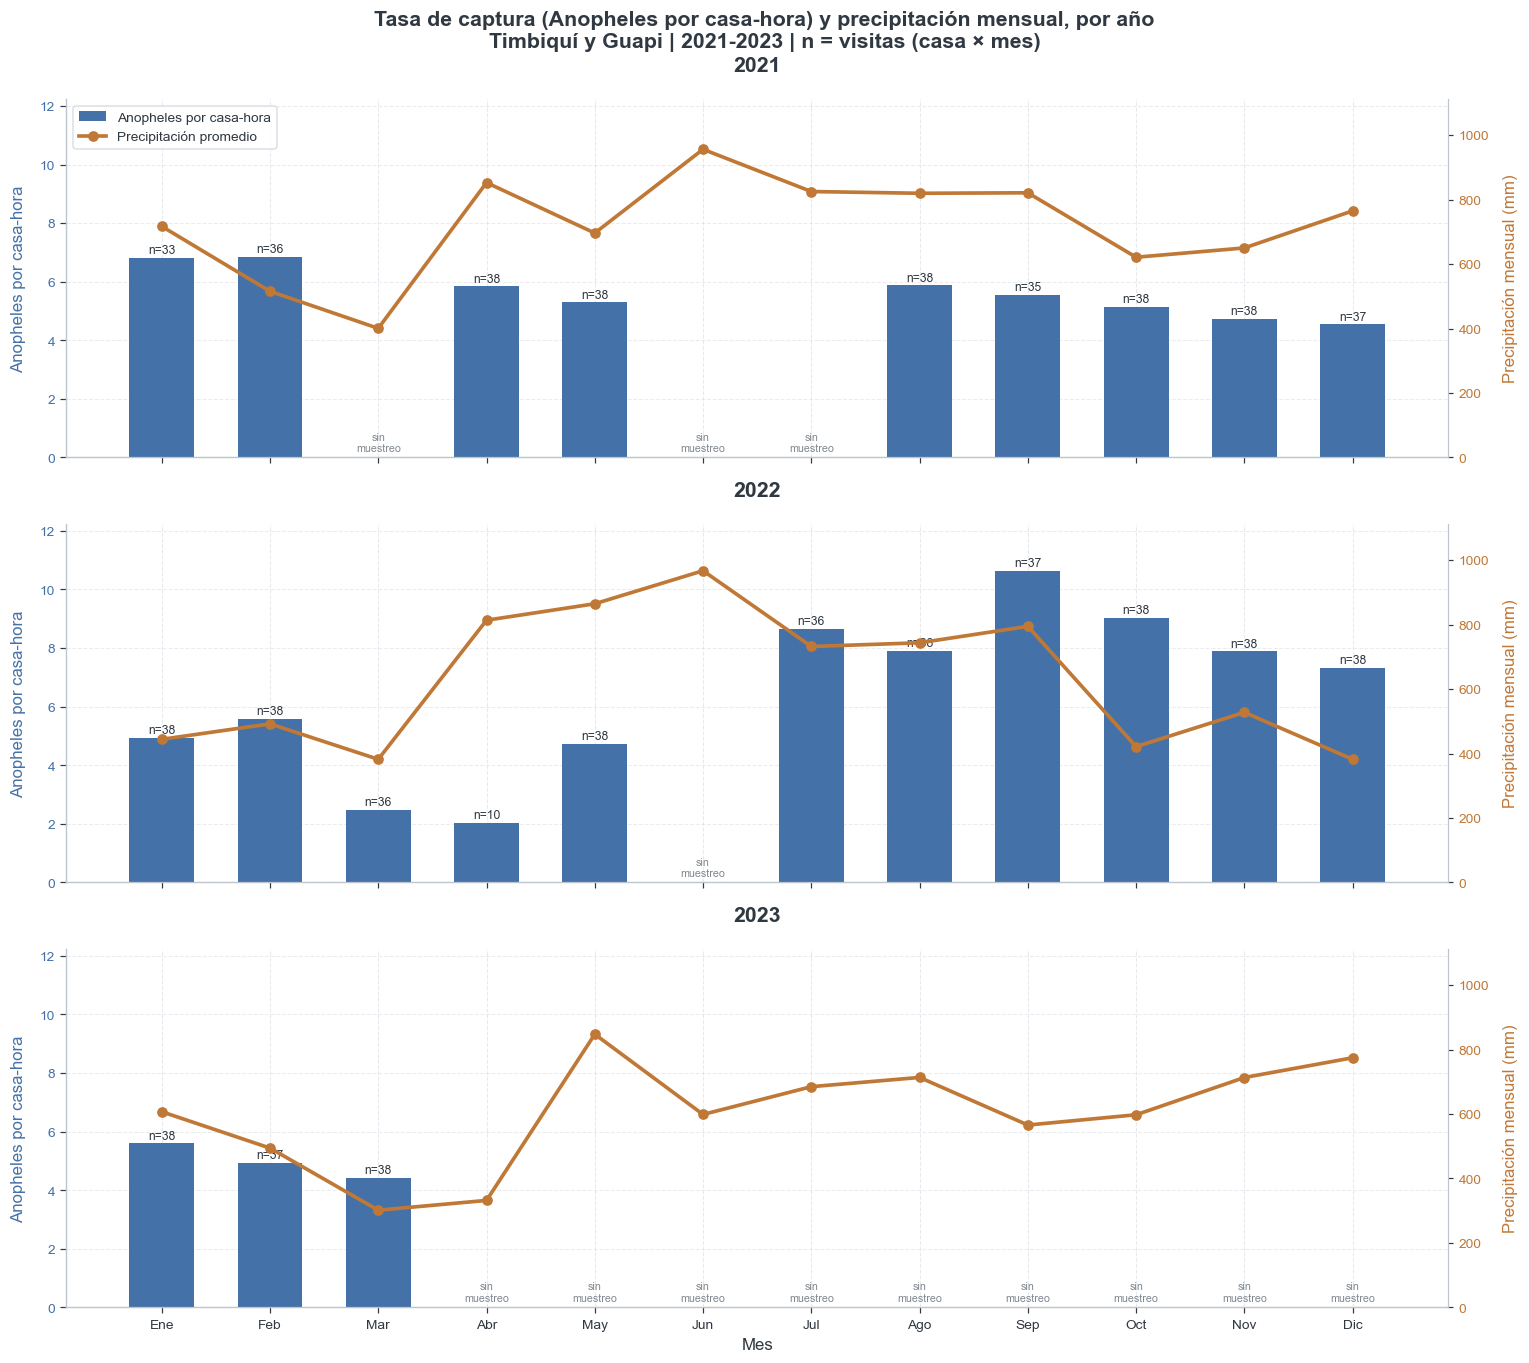

,Año,Mes_Nombre,Visitas,Total_Mosquitos,Casa_Horas,Tasa,Precipitacion_Promedio_mm
0,2021,Ene,33,5155.0,756.0,6.82,717.00
1,2021,Feb,36,9295.0,1358.0,6.84,515.50
3,2021,Abr,38,7922.0,1356.0,5.84,852.63
4,2021,May,38,5398.0,1020.0,5.29,696.20
7,2021,Ago,38,8177.0,1392.0,5.87,819.60
8,2021,Sep,35,2800.0,504.0,5.56,821.07
9,2021,Oct,38,9357.0,1824.0,5.13,621.23
10,2021,Nov,38,10954.0,2316.0,4.73,650.00
11,2021,Dic,37,5560.0,1224.0,4.54,765.00
12,2022,Ene,38,7475.0,1512.0,4.94,444.00


In [163]:
# ============================================================
# 9. TASA DE CAPTURA MENSUAL VS PRECIPITACIÓN, SEPARADAS POR AÑO
# ============================================================

# ============================================================
# 1. TASA POR AÑO-MES (Σ individuos / Σ casa-horas)
# ============================================================
vis_mes = visitas.copy()
vis_mes['Año'] = vis_mes['campania'].dt.year
vis_mes['Mes_Num'] = vis_mes['campania'].dt.month

datos_mensuales = (
    vis_mes.groupby(['Año', 'Mes_Num'])
    .agg(Total_Mosquitos=('N', 'sum'),
         Casa_Horas=('casa_horas', 'sum'),
         Visitas=('casa', 'size'))
    .reset_index()
)
datos_mensuales['Tasa'] = datos_mensuales['Total_Mosquitos'] / datos_mensuales['Casa_Horas']

# ============================================================
# 2. PRECIPITACIÓN MENSUAL POR AÑO (IDEAM)
# ============================================================
# La variable lluvia ya está filtrada para 2021-2023 y excluye Gorgona (sección 7).
# Se promedian las estaciones disponibles en cada año-mes.
precipitacion = (
    lluvia.groupby(['Año', 'Mes'])['Valor']
    .mean()
    .rename('Precipitacion_Promedio_mm')
    .reset_index()
    .rename(columns={'Mes': 'Mes_Num'})
)

anios = sorted(datos_mensuales['Año'].unique())
rejilla = pd.MultiIndex.from_product([anios, range(1, 13)], names=['Año', 'Mes_Num']).to_frame(index=False)
datos_mensuales = (rejilla
                   .merge(datos_mensuales, on=['Año', 'Mes_Num'], how='left')
                   .merge(precipitacion, on=['Año', 'Mes_Num'], how='left'))
datos_mensuales['Visitas'] = datos_mensuales['Visitas'].fillna(0).astype(int)

meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
         'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
datos_mensuales['Mes_Nombre'] = datos_mensuales['Mes_Num'].map(dict(enumerate(meses, start=1)))

# ============================================================
# 3. GRÁFICA: UN PANEL POR AÑO
# ============================================================
fig, axes = plt.subplots(len(anios), 1, figsize=(14, 4.2 * len(anios)), sharex=True)
axes = np.atleast_1d(axes)
ejes_lluvia = []

y_max_tasa = datos_mensuales['Tasa'].max() * 1.15
y_max_lluvia = datos_mensuales['Precipitacion_Promedio_mm'].max() * 1.15

for ax1, anio in zip(axes, anios):
    d = datos_mensuales[datos_mensuales['Año'] == anio]

    ax1.bar(d['Mes_Num'], d['Tasa'], width=0.6,
            color=COLORES['principal'], label='Anopheles por casa-hora', zorder=3)

    # Número de visitas sobre cada barra; 'sin muestreo' cuando no hubo visitas
    for _, r in d.iterrows():
        if r['Visitas'] > 0:
            ax1.annotate(f"n={r['Visitas']}", (r['Mes_Num'], r['Tasa']),
                         textcoords='offset points', xytext=(0, 3), ha='center',
                         fontsize=8, color=COLORES['texto'])
        else:
            ax1.annotate('sin\nmuestreo', (r['Mes_Num'], 0), textcoords='offset points',
                         xytext=(0, 4), ha='center', fontsize=7, color=COLORES['gris'])

    ax1.set_ylim(0, y_max_tasa)
    formato_grafica(ax1, titulo=str(anio), ylabel='Anopheles por casa-hora')
    ax1.tick_params(axis='y', labelcolor=COLORES['principal'])
    ax1.yaxis.label.set_color(COLORES['principal'])

    ax2 = ax1.twinx()
    ejes_lluvia.append(ax2)
    ax2.plot(d['Mes_Num'], d['Precipitacion_Promedio_mm'], color=COLORES['secundario'],
             marker='o', markersize=6, linewidth=2.4, label='Precipitación promedio', zorder=5)
    ax2.set_ylim(0, y_max_lluvia)
    ax2.set_ylabel('Precipitación mensual (mm)', color=COLORES['secundario'], labelpad=9)
    ax2.tick_params(axis='y', labelcolor=COLORES['secundario'])
    ax2.grid(False)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(True)
    ax2.spines['right'].set_color('#BFC5CC')

axes[-1].set_xticks(range(1, 13))
axes[-1].set_xticklabels(meses)
axes[-1].set_xlabel('Mes')

h1, l1 = axes[0].get_legend_handles_labels()
h2, l2 = ejes_lluvia[0].get_legend_handles_labels()
axes[0].legend(h1 + h2, l1 + l2, loc='upper left')

fig.suptitle('Tasa de captura (Anopheles por casa-hora) y precipitación mensual, por año\n'
             'Timbiquí y Guapi | 2021-2023 | n = visitas (casa × mes)',
             fontsize=14, fontweight='bold', color=COLORES['texto'])
plt.tight_layout()
plt.show()

display(
    datos_mensuales.dropna(subset=['Tasa'])
    [['Año', 'Mes_Nombre', 'Visitas', 'Total_Mosquitos', 'Casa_Horas', 'Tasa',
      'Precipitacion_Promedio_mm']]
    .round(2)
)

## 10. Capturas por campaña y precipitación

**Pregunta:** ¿en los meses con más lluvia se capturan más *Anopheles*?

**Cómo se arma cada punto:** un punto es **un mes de muestreo en un municipio**. Se suman los individuos y las casa-horas de todas las localidades del municipio en ese mes. Se agrupa así porque las localidades de un mismo municipio y mes comparten la misma lluvia; separarlas repetiría el mismo valor de lluvia varias veces.

**Lluvia:** promedio diario (mm/día) de las estaciones del municipio (Timbiquí: Timbiquí y Saija; Guapi: Aeropuerto Guapi y Bocas de Napi), en tres ventanas:

- **Durante la campaña:** los días en que se muestreó. Afecta la actividad de los mosquitos esa noche.
- **14 y 30 días antes:** la lluvia previa crea criaderos, y los adultos aparecen 2 a 3 semanas después.

**Medidas de captura comparadas con la lluvia:**

| Medida | Qué dice | ¿Sirve para responder la pregunta? |
|---|---|---|
| Anopheles capturados ($N$) | Total del mes | No por sí sola: sube si se muestrearon más casas o noches |
| Esfuerzo (casa-horas) | Cuánto se muestreó | Es un control: si se correlaciona con la lluvia, $N$ estaría sesgado |
| **Anopheles por casa-hora** | Captura normalizada (sección 8) | **Sí**: es la medida que se grafica |

Puntos (municipio × mes): 45 | campañas de localidad agrupadas: 505


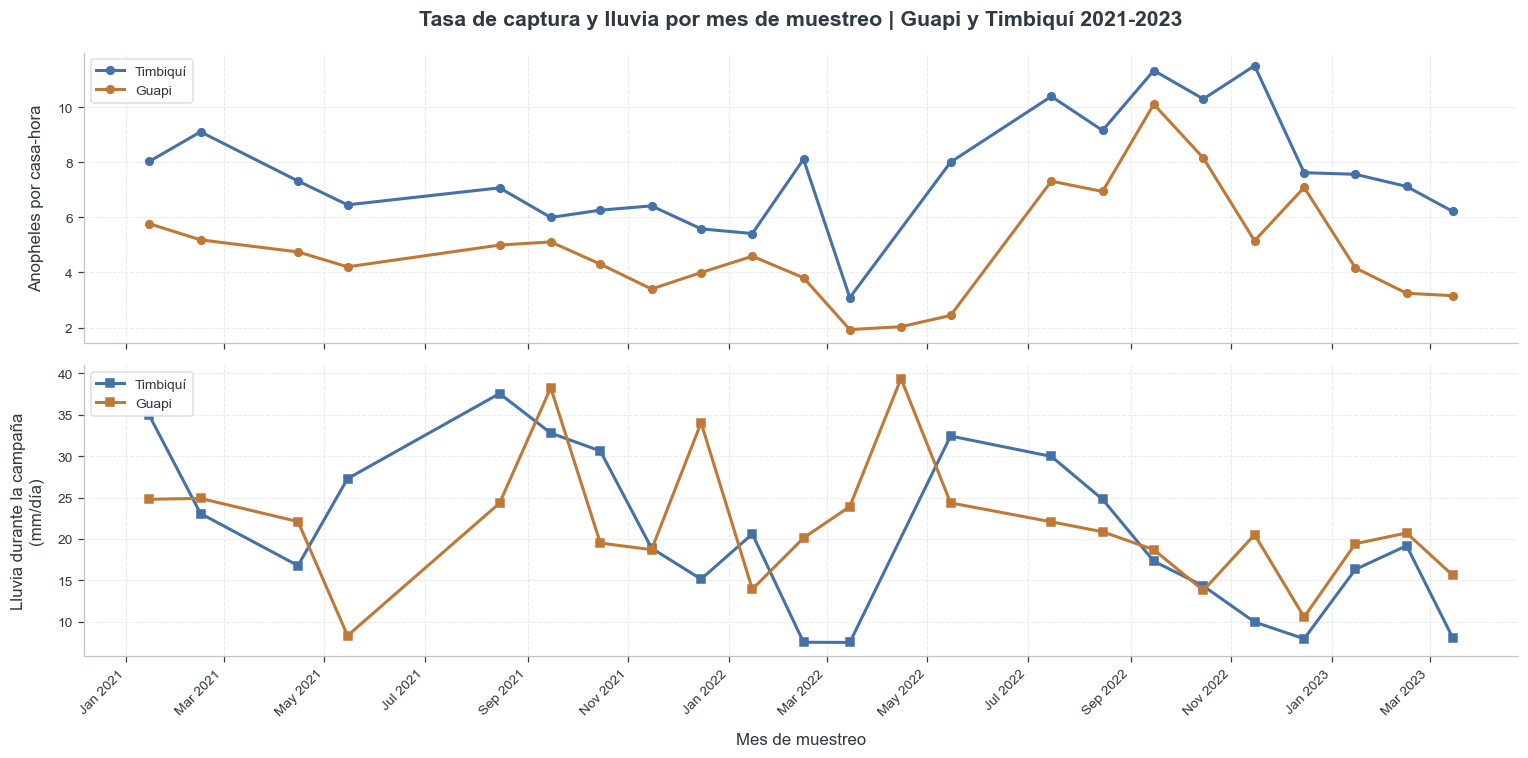

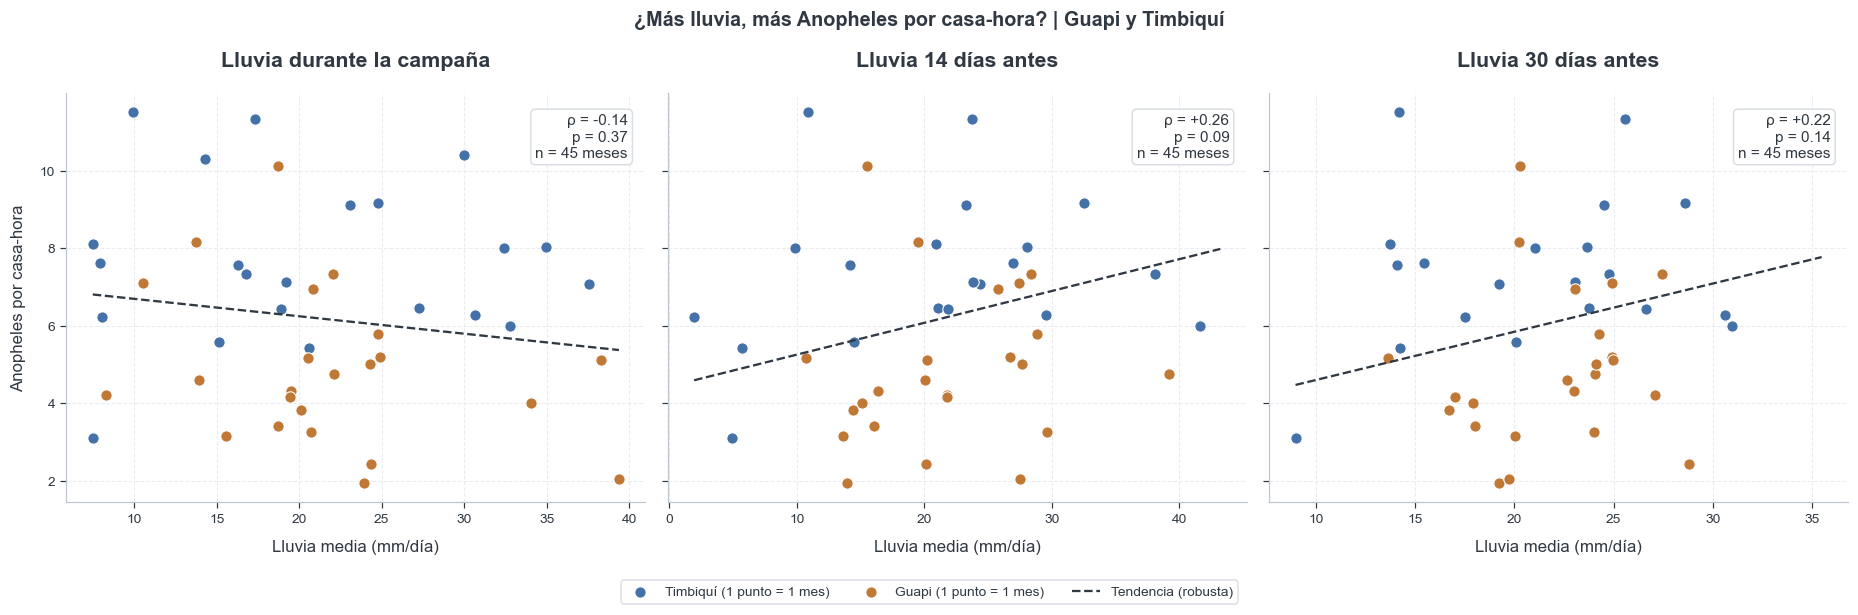

CORRELACIÓN DE SPEARMAN ENTRE LLUVIA Y CADA MEDIDA DE CAPTURA (un punto por municipio × mes)


,Durante la campaña,14 días antes,30 días antes
Medida,,,
Anopheles capturados,ρ = -0.32 (p = 0.03),ρ = +0.10 (p = 0.52),ρ = +0.11 (p = 0.46)
Esfuerzo (casa-horas),ρ = -0.23 (p = 0.13),ρ = -0.05 (p = 0.72),ρ = +0.04 (p = 0.80)
Anopheles por casa-hora,ρ = -0.14 (p = 0.37),ρ = +0.26 (p = 0.09),ρ = +0.22 (p = 0.14)


In [164]:
# ============================================================
# 10. CAPTURAS POR CAMPAÑA Y PRECIPITACIÓN (GUAPI Y TIMBIQUÍ)
# ============================================================

# ============================================================
# 1. LLUVIA DIARIA POR MUNICIPIO
# ============================================================
# Promedio (no suma) de las estaciones del municipio que reportaron ese día,
# para que el valor no dependa de cuántas estaciones hay.
ESTACIONES_MUNICIPIO = {
    'TIMBIQUI [53050020]': 'Timbiquí',
    'SAIJA [53060020]': 'Timbiquí',
    'AEROPUERTO GUAPI - AUT [53045040]': 'Guapi',
    'BOCAS DE NAPI [53040010]': 'Guapi',
}

lluvia_dia = prep_diaria.copy()
lluvia_dia['Fecha'] = pd.to_datetime(lluvia_dia['Fecha'], errors='coerce').dt.normalize()
lluvia_dia['Valor'] = pd.to_numeric(lluvia_dia['Valor'], errors='coerce')
lluvia_dia['county'] = lluvia_dia['NombreEstacion'].map(ESTACIONES_MUNICIPIO)
lluvia_dia = (
    lluvia_dia.dropna(subset=['Fecha', 'Valor', 'county'])
    .groupby(['county', 'Fecha'])['Valor'].mean()
)

def lluvia_media(municipio, desde, hasta, cobertura_min=0.7):
    """Lluvia media diaria (mm/día) entre dos fechas (incluidas).
    NaN si hay datos para menos del 70 % de los días."""
    serie = lluvia_dia.loc[municipio].reindex(pd.date_range(desde, hasta, freq='D'))
    return serie.mean() if serie.notna().mean() >= cobertura_min else np.nan

# ============================================================
# 2. LLUVIA EN TRES VENTANAS PARA CADA CAMPAÑA
# ============================================================
# Durante: lluvia de los días de la campaña (afecta la actividad de picadura).
# 14 y 30 días antes: lluvia previa (crea criaderos; efecto con rezago).
VENTANAS = ['Durante la campaña', '14 días antes', '30 días antes']
dia = pd.Timedelta(days=1)
campanias['Durante la campaña'] = [lluvia_media(m, i, f) for m, i, f
                                   in zip(campanias['county'], campanias['inicio'], campanias['fin'])]
campanias['14 días antes'] = [lluvia_media(m, i - 14 * dia, i - dia)
                              for m, i in zip(campanias['county'], campanias['inicio'])]
campanias['30 días antes'] = [lluvia_media(m, i - 30 * dia, i - dia)
                              for m, i in zip(campanias['county'], campanias['inicio'])]

# ============================================================
# 3. UN PUNTO POR MUNICIPIO Y MES
# ============================================================
# Las localidades de un mismo municipio y mes comparten la misma lluvia, así que
# se agrupan: cada punto es un mes de muestreo en un municipio.
def por_mes(tabla):
    m = (tabla.groupby(['county', 'campania'])
         .agg(N=('N', 'sum'), casa_horas=('casa_horas', 'sum'),
              inicio=('inicio', 'min'), fin=('fin', 'max'),
              **{v: (v, 'mean') for v in VENTANAS})
         .reset_index())
    m['tasa'] = m['N'] / m['casa_horas']          # Σ individuos / Σ casa-horas
    m['fecha'] = m['campania'].dt.to_timestamp() + pd.Timedelta(days=14)
    return m

MEDIDAS = {
    'N': 'Anopheles capturados',
    'casa_horas': 'Esfuerzo (casa-horas)',
    'tasa': 'Anopheles por casa-hora',
}

def tabla_correlaciones(m):
    """ρ de Spearman (y p) entre cada medida de captura y cada ventana de lluvia."""
    filas = []
    for col, nombre in MEDIDAS.items():
        fila = {'Medida': nombre}
        for v in VENTANAS:
            d = m[[col, v]].dropna()
            r = stats.spearmanr(d[col], d[v])
            fila[v] = f"ρ = {r.statistic:+.2f} (p = {r.pvalue:.2f})"
        filas.append(fila)
    return pd.DataFrame(filas).set_index('Medida')

# ============================================================
# 4. GRÁFICAS
# ============================================================
COLOR_MUNICIPIO = {'Timbiquí': COLORES['principal'], 'Guapi': COLORES['secundario']}

def graficar_linea_tiempo(m, titulo, nombres=None):
    """Contexto: tasa y lluvia de cada mes, en paneles separados."""
    nombres = nombres or {}
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    for municipio, color in COLOR_MUNICIPIO.items():
        d = m[m['county'] == municipio].sort_values('fecha')
        if d.empty:
            continue
        etiqueta = nombres.get(municipio, municipio)
        ax1.plot(d['fecha'], d['tasa'], marker='o', color=color, label=etiqueta)
        ax2.plot(d['fecha'], d['Durante la campaña'], marker='s', color=color, label=etiqueta)
    formato_grafica(ax1, titulo=titulo, ylabel='Anopheles por casa-hora')
    formato_grafica(ax2, xlabel='Mes de muestreo', ylabel='Lluvia durante la campaña\n(mm/día)')
    ax1.legend(loc='upper left')
    ax2.legend(loc='upper left')
    ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.setp(ax2.get_xticklabels(), rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

def graficar_correlacion(m, titulo, nombres=None):
    """Lluvia (eje x) vs tasa de captura (eje y): un panel por ventana de lluvia."""
    nombres = nombres or {}
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True)
    for ax, v in zip(axes, VENTANAS):
        for municipio, color in COLOR_MUNICIPIO.items():
            d = m[m['county'] == municipio]
            if not d.empty:
                ax.scatter(d[v], d['tasa'], s=55, color=color, edgecolor='white', linewidth=0.7,
                           label=f'{nombres.get(municipio, municipio)} (1 punto = 1 mes)', zorder=3)
        d = m[[v, 'tasa']].dropna()
        r = stats.spearmanr(d[v], d['tasa'])
        # Tendencia de Theil-Sen (mediana de pendientes): robusta a meses extremos,
        # coherente con Spearman. Es solo una guía visual.
        pend, inter, _, _ = stats.theilslopes(d['tasa'], d[v])
        xs = np.linspace(d[v].min(), d[v].max(), 50)
        ax.plot(xs, inter + pend * xs, color=COLORES['texto'], linestyle='--',
                linewidth=1.5, label='Tendencia (robusta)', zorder=4)
        ax.text(0.97, 0.95, f"ρ = {r.statistic:+.2f}\np = {r.pvalue:.2f}\nn = {len(d)} meses",
                transform=ax.transAxes, ha='right', va='top', fontsize=10,
                bbox=dict(boxstyle='round', facecolor='white', edgecolor=COLORES['gris_claro']))
        formato_grafica(ax, titulo=f'Lluvia {v.lower()}', xlabel='Lluvia media (mm/día)',
                        ylabel='Anopheles por casa-hora' if ax is axes[0] else None,
                        grid_axis='both')
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc='lower center', ncol=len(h), bbox_to_anchor=(0.5, -0.07))
    fig.suptitle(titulo, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ============================================================
# 5. RESULTADOS: GUAPI Y TIMBIQUÍ
# ============================================================
meses_mun = por_mes(campanias)
print(f"Puntos (municipio × mes): {len(meses_mun)} | "
      f"campañas de localidad agrupadas: {len(campanias)}")

graficar_linea_tiempo(meses_mun, 'Tasa de captura y lluvia por mes de muestreo | Guapi y Timbiquí 2021-2023')
graficar_correlacion(meses_mun, '¿Más lluvia, más Anopheles por casa-hora? | Guapi y Timbiquí')

print('CORRELACIÓN DE SPEARMAN ENTRE LLUVIA Y CADA MEDIDA DE CAPTURA (un punto por municipio × mes)')
display(tabla_correlaciones(meses_mun))

## 11. Capturas por campaña y precipitación en Cheté

**Pregunta:** ¿se observa la misma relación en la localidad de interés?

Cheté: 22 meses de muestreo | individuos: 7418 | casa-horas: 1782


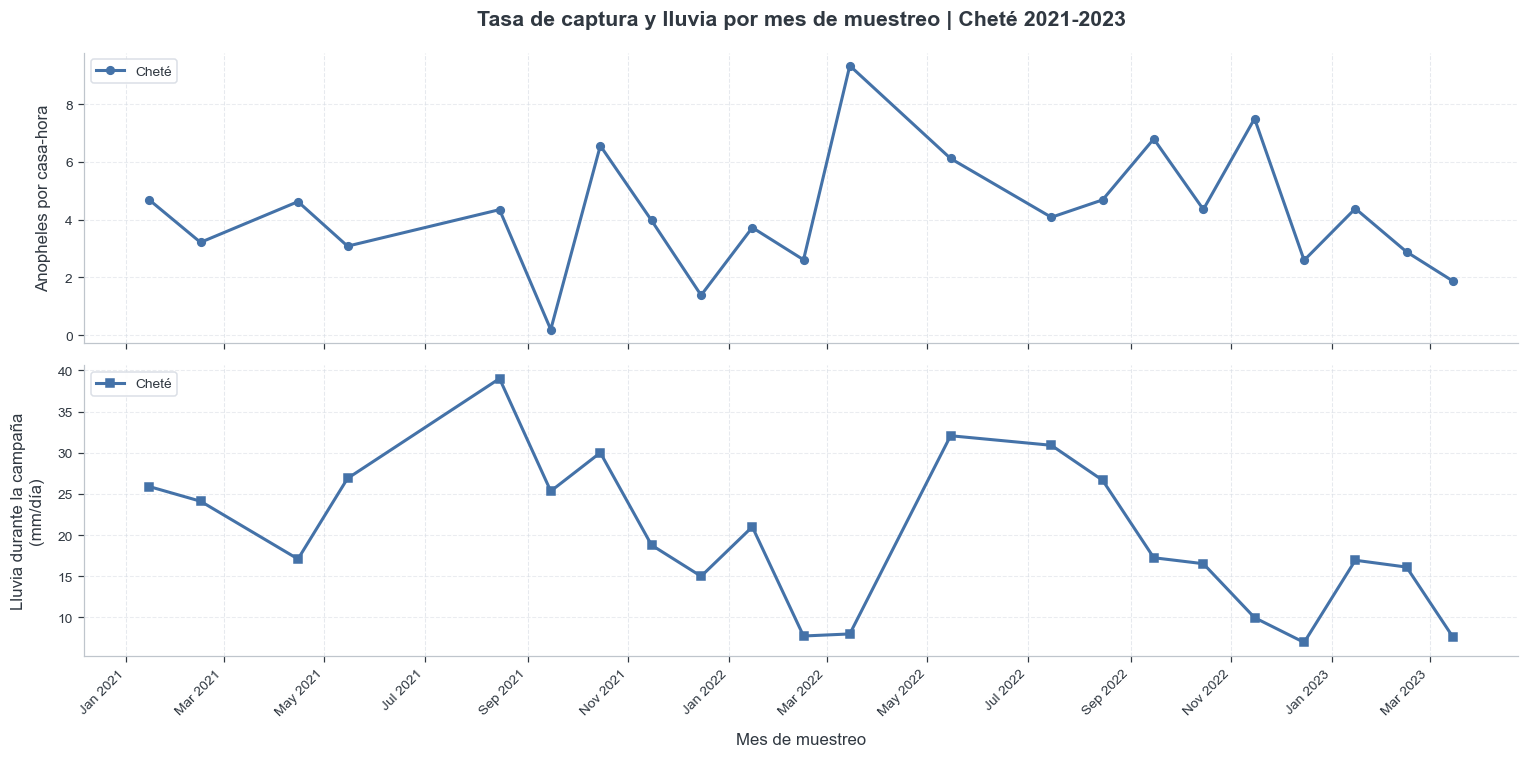

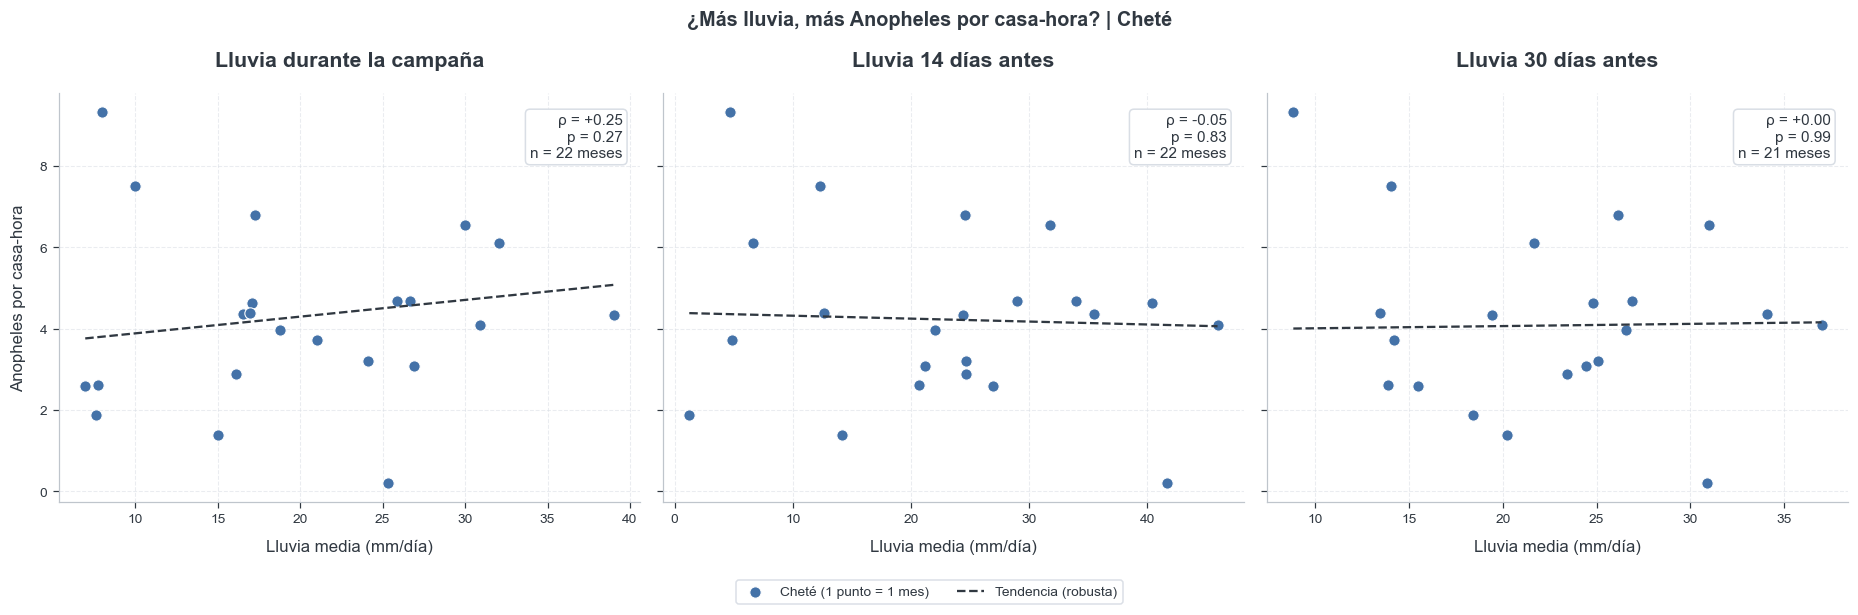

CORRELACIÓN DE SPEARMAN ENTRE LLUVIA Y CADA MEDIDA DE CAPTURA (un punto por mes)


,Durante la campaña,14 días antes,30 días antes
Medida,,,
Anopheles capturados,ρ = +0.26 (p = 0.24),ρ = +0.06 (p = 0.80),ρ = +0.15 (p = 0.53)
Esfuerzo (casa-horas),ρ = -0.15 (p = 0.52),ρ = +0.04 (p = 0.85),ρ = +0.15 (p = 0.52)
Anopheles por casa-hora,ρ = +0.25 (p = 0.27),ρ = -0.05 (p = 0.83),ρ = +0.00 (p = 0.99)


,campania,N,casa_horas,tasa,Durante la campaña,14 días antes,30 días antes
0,2021-01,328,70.0,4.69,25.89,29.00,NaN
1,2021-02,180,56.0,3.21,24.11,24.64,25.07
2,2021-04,333,72.0,4.62,17.09,40.36,24.83
3,2021-05,185,60.0,3.08,26.88,21.21,24.45
4,2021-08,313,72.0,4.35,39.00,24.43,19.40
5,2021-09,14,72.0,0.19,25.33,41.64,30.90
6,2021-10,630,96.0,6.56,30.00,31.79,31.00
7,2021-11,477,120.0,3.98,18.79,22.07,26.57
8,2021-12,83,60.0,1.38,15.00,14.14,20.20
9,2022-01,313,84.0,3.73,21.00,4.86,14.22


In [165]:
# ============================================================
# 11. CAPTURAS POR CAMPAÑA Y PRECIPITACIÓN EN CHETÉ
# ============================================================
# Reutiliza la lluvia por campaña y las funciones de la sección 10.
chete_mes = por_mes(campanias[campanias['locality'] == 'Cheté'])

print(f"Cheté: {len(chete_mes)} meses de muestreo | individuos: {chete_mes['N'].sum():.0f} | "
      f"casa-horas: {chete_mes['casa_horas'].sum():.0f}")

graficar_linea_tiempo(chete_mes, 'Tasa de captura y lluvia por mes de muestreo | Cheté 2021-2023',
                      nombres={'Timbiquí': 'Cheté'})
graficar_correlacion(chete_mes, '¿Más lluvia, más Anopheles por casa-hora? | Cheté',
                     nombres={'Timbiquí': 'Cheté'})

print('CORRELACIÓN DE SPEARMAN ENTRE LLUVIA Y CADA MEDIDA DE CAPTURA (un punto por mes)')
display(tabla_correlaciones(chete_mes))

display(
    chete_mes[['campania', 'N', 'casa_horas', 'tasa'] + VENTANAS].round(2)
)

## 12. Equivalencias entre localidades del río Timbiquí cercanas a Cheté

**Pregunta:** ¿las localidades de la ribera del río Timbiquí más cercanas a Cheté son indistinguibles de Cheté? Si lo fueran, podríamos sumar sus datos a los de Cheté para estimar su tasa de captura con más información; si no, mezclarlas sesgaría la estimación.

**Localidades incluidas:** Cheté, Coteje, Velásquez y San Miguel del Río (latitud 2,64–2,67, a pocos km de Cheté sobre el río Timbiquí). Se excluyen las del río Saija (Puerto Saija, Nueva Esperanza), las de la cabecera municipal (Calle del Pueblo, Mataco, Brazo Corto) y El Charco, más alejada río abajo.

**Decisiones de análisis:**

- **Unidad de observación:** la *visita* = una casa en una campaña mensual. Una fila de `occurrence.txt` es especie × casa × campaña y acumula varias noches, así que se suman las especies de la visita.
- **Variable comparada:** *Anopheles* por casa-hora = individuos / (noches × horas por noche). Esto corrige que las visitas tengan entre 1 y 6 noches y 12 o 14 h por noche. Se trabaja en escala logarítmica porque la tasa es muy asimétrica.
- **Casa:** se normaliza `parentEventID` (p. ej. `Mataco_01` es la casa *Mataco* en la campaña 01, no una casa distinta).
- **Campaña (mes):** se toma de `verbatimEventDate`, porque `eventDate` tiene nulos y errores de año.
- **No independencia:** las visitas repetidas a una misma casa y las visitas del mismo mes no son independientes

In [166]:
# ============================================================
# 12.1. UNIDAD DE OBSERVACIÓN: VISITA = CASA × CAMPAÑA
# ============================================================
from scipy import stats

MESES_ES = {'enero': 1, 'febrero': 2, 'marzo': 3, 'abril': 4, 'mayo': 5, 'junio': 6,
            'julio': 7, 'agosto': 8, 'septiembre': 9, 'octubre': 10,
            'noviembre': 11, 'diciembre': 12}

# Localidades de la ribera del río Timbiquí cercanas a Cheté
LOCALIDADES_RIBERA = ['Cheté', 'Coteje', 'Velásquez', 'San Miguel del Río']

tim = df[df['municipality'].astype('string').str.contains('Timbiqu', na=False)
        & df['locality'].isin(LOCALIDADES_RIBERA)].copy()
assert set(tim['locality']) == set(LOCALIDADES_RIBERA)
tim['individualCount'] = pd.to_numeric(tim['individualCount'], errors='coerce')

# --- Casa: parentEventID normalizado ------------------------------------
# 'Mataco_01' (sin guion) = casa 'Mataco', campaña 01;  'Saija_1-01' = casa 'Saija1'.
def casa_desde_ids(row):
    if '-' in row['eventID']:
        return row['parentEventID'].replace('_', '')
    return row['eventID'].rsplit('_', 1)[0]

tim['casa'] = tim.apply(casa_desde_ids, axis=1)

# --- Campaña: mes-año tomado de verbatimEventDate -----------------------
# eventDate tiene nulos y errores de año (p. ej. Coteje1-20 dice 2022 y es enero 2023).
# verbatimEventDate trae 'mes año' o, cuando es un intervalo, una fecha de inicio correcta.
def campania_desde_verbatim(v):
    v = str(v).strip().lower()
    partes = v.split()
    if len(partes) == 2 and partes[0] in MESES_ES:
        return pd.Period(year=int(partes[1]), month=MESES_ES[partes[0]], freq='M')
    return pd.Period(v.split('/')[0], freq='M')

tim['campania'] = tim['verbatimEventDate'].map(campania_desde_verbatim)

# --- Esfuerzo -----------------------------------------------------------
tim['horas'] = tim['samplingEffort'].str.extract(r'(\d+)\s*h')[0].astype(float)
tim['noches'] = tim['samplingEffort'].str.extract(r'(\d+)\s*noche')[0].astype(float)
tim['n_albimanus'] = np.where(tim['scientificName'] == 'Anopheles albimanus',
                              tim['individualCount'], 0)

# Una fila = especie × casa × campaña. El número de noches puede diferir entre
# especies de la misma visita; se toma el máximo como esfuerzo de la visita.
ev = (tim.groupby(['locality', 'casa', 'campania'])
         .agg(N=('individualCount', 'sum'),
              N_albimanus=('n_albimanus', 'sum'),
              noches=('noches', 'max'),
              horas=('horas', 'max'))
         .reset_index())
ev['casa_horas'] = ev['noches'] * ev['horas']
ev['tasa'] = ev['N'] / ev['casa_horas']          # Anopheles por casa-hora
ev['log_tasa'] = np.log(ev['tasa'])

print('Registros (ribera del río Timbiquí):', len(tim), '| sin eventDate:', tim['eventDate'].isna().sum(),
      '(recuperados desde verbatimEventDate)')
print('Visitas casa × campaña:', len(ev), '| casas:', ev['casa'].nunique(),
      '| localidades:', ev['locality'].nunique(), '| campañas:', ev['campania'].nunique())

resumen_loc = (ev.groupby('locality')
                 .agg(casas=('casa', 'nunique'), visitas=('casa', 'size'),
                      individuos=('N', 'sum'),
                      tasa_mediana=('tasa', 'median'),
                      tasa_q1=('tasa', lambda s: s.quantile(.25)),
                      tasa_q3=('tasa', lambda s: s.quantile(.75)),
                      pct_albimanus=('N_albimanus', 'sum'))
                 .sort_values('tasa_mediana'))
resumen_loc['pct_albimanus'] = 100 * resumen_loc['pct_albimanus'] / resumen_loc['individuos']
display(resumen_loc.round(2))

Registros (ribera del río Timbiquí): 286 | sin eventDate: 5 (recuperados desde verbatimEventDate)
Visitas casa × campaña: 154 | casas: 7 | localidades: 4 | campañas: 22


,casas,visitas,individuos,tasa_mediana,tasa_q1,tasa_q3,pct_albimanus
locality,,,,,,,
Cheté,2,44,7418,2.81,1.38,5.90,98.23
Velásquez,1,22,2818,2.82,1.64,3.25,25.94
Coteje,2,44,12236,4.24,1.71,11.23,99.77
San Miguel del Río,2,44,14309,5.52,3.66,9.54,4.77


### 12.2. Distribución de la tasa por localidad

Cada punto es una visita y su color identifica la casa. Si las localidades fueran equivalentes, las cajas estarían a la misma altura. El eje está en escala log porque la tasa abarca varios órdenes de magnitud (sección 8).

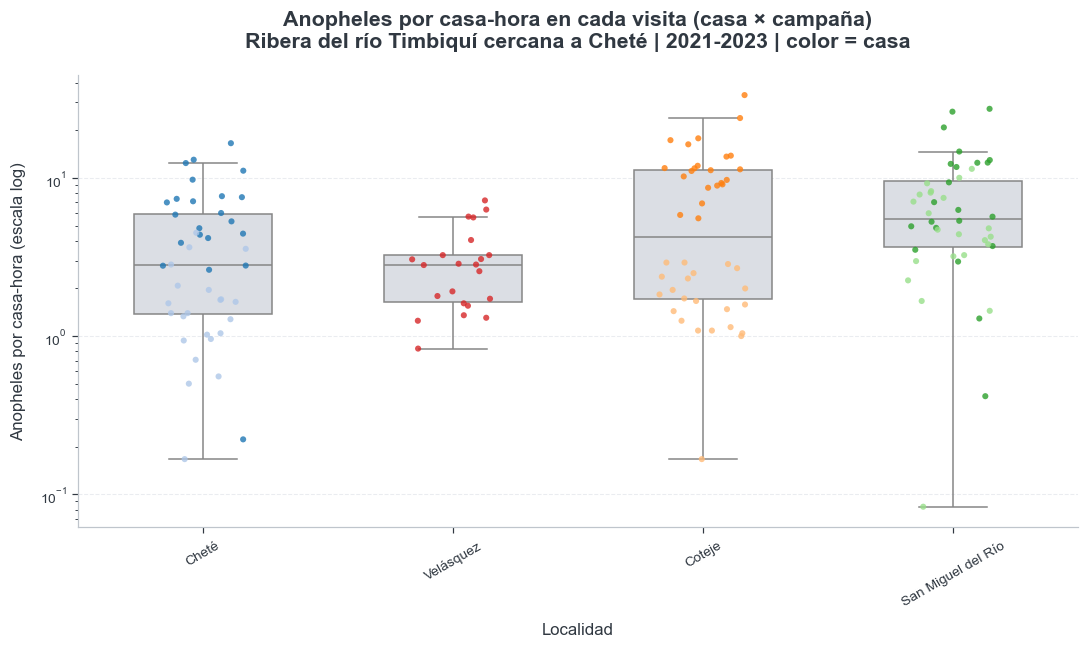

In [167]:
# ============================================================
# 12.2. DISTRIBUCIÓN DE LA TASA DE CAPTURA POR LOCALIDAD
# ============================================================
orden = resumen_loc.index.tolist()

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=ev, x='locality', y='tasa', order=orden, ax=ax,
            color=COLORES['gris_claro'], fliersize=0, width=0.55)
sns.stripplot(data=ev, x='locality', y='tasa', order=orden, ax=ax,
              hue='casa', palette='tab20', size=4, jitter=0.18, alpha=0.8, legend=False)
ax.set_yscale('log')   # la tasa abarca varios órdenes de magnitud (sección 8)
ax.tick_params(axis='x', rotation=30)
formato_grafica(ax,
                titulo='Anopheles por casa-hora en cada visita (casa × campaña)\n'
                       'Ribera del río Timbiquí cercana a Cheté | 2021-2023 | color = casa',
                xlabel='Localidad', ylabel='Anopheles por casa-hora (escala log)')
plt.tight_layout()
plt.show()

### 12.4. Composición de especies

Aunque dos localidades tengan tasas parecidas, pueden no ser equivalentes si capturan especies distintas. El chi-cuadrado sobre individuos se muestra solo como referencia; la prueba válida es la permutación entre casas sobre la proporción de *An. albimanus*.

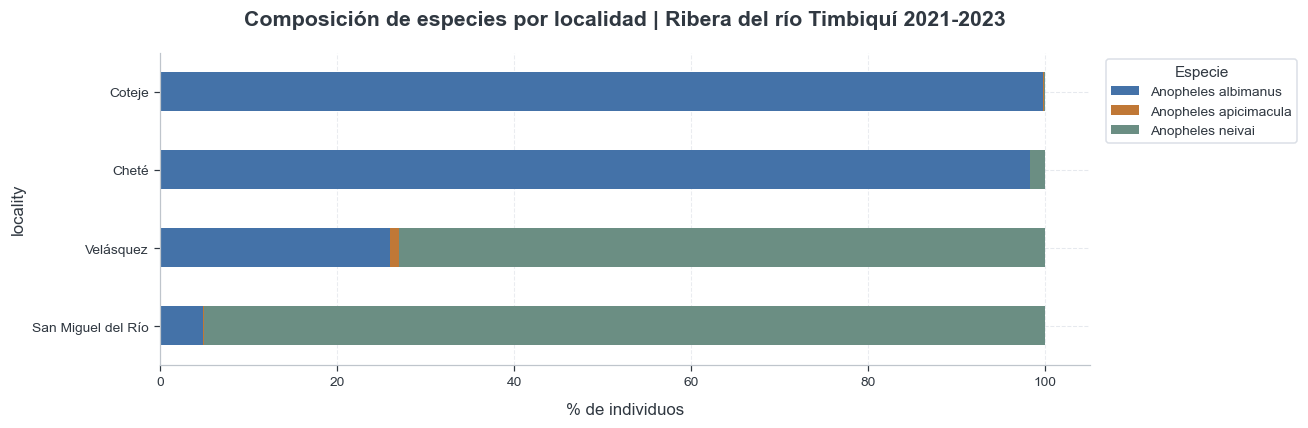

In [177]:
# ============================================================
# 12.4. COMPOSICIÓN DE ESPECIES ENTRE LOCALIDADES
# ============================================================
rng = np.random.default_rng(2026)

# Permutación a nivel de casa: cada casa es una unidad y se permutan las etiquetas
# de localidad entre casas (respeta que las visitas a una casa no son independientes).
# Estadístico: suma de cuadrados entre localidades (ponderada por n.º de casas).
def ss_entre(valores, etiquetas):
    d = pd.DataFrame({'v': valores, 'g': etiquetas})
    medias = d.groupby('g')['v'].agg(['mean', 'size'])
    return np.sum(medias['size'] * (medias['mean'] - d['v'].mean()) ** 2)

def permutacion_casas(valores, etiquetas, n_perm=10000):
    obs = ss_entre(valores, etiquetas)
    perm = np.array([ss_entre(valores, rng.permutation(etiquetas)) for _ in range(n_perm)])
    return obs, (1 + np.sum(perm >= obs)) / (n_perm + 1)

comp = (tim.groupby(['locality', 'scientificName'])['individualCount'].sum()
           .unstack(fill_value=0))
comp_pct = comp.div(comp.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 4))
comp_pct.loc[comp_pct.sort_values('Anopheles albimanus').index].plot(
    kind='barh', stacked=True, ax=ax,
    color=[COLORES['principal'], COLORES['secundario'], COLORES['terciario']])
formato_grafica(ax, titulo='Composición de especies por localidad | Ribera del río Timbiquí 2021-2023',
                xlabel='% de individuos', ylabel='', grid_axis='x')
ax.legend(title='Especie', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 13. Validación de H1: la captura es proporcional al esfuerzo

**Hipótesis (H1):** el número de *Anopheles* capturados es proporcional al esfuerzo de muestreo, con una tasa por casa-hora relativamente estable. Si se cumple:

$$
\hat N_{\text{4 noches}} = \text{tasa} \times \text{horas por noche} \times 4 \text{ noches} \times \text{casas}
$$

Es la misma estructura del modelo de Fermi (tasa × colectores × horas), así que permite contrastarlo directamente. Los demás supuestos de Fermi (interior frente a exterior, franjas horarias, proporción $p_a$) **no se pueden verificar** con este dataset: todos los registros son "En domicilio", cubren la noche completa (17:00–05:00) y solo incluyen *Anopheles*.

La validación tiene tres pasos:

1. **¿Las capturas crecen proporcionalmente con el esfuerzo?** Pendiente $b$ en escala log-log ($b = 1$ significa proporcional).
2. **¿Qué tan estable es la tasa en Cheté?** Distribución por casa.
3. **Predicción para 4 noches en Cheté** y comparación con Fermi.

### 13.1. Capturas frente a esfuerzo (log-log)

Cada punto es una visita (casa × mes). Para que la pendiente no mezcle casas muy productivas con casas muy muestreadas, se estima **dentro de cada casa**: cada visita se compara con el promedio de su propia casa, en escala log. El IC 95 % se obtiene remuestreando meses completos (bootstrap), porque las visitas de un mismo mes no son independientes.

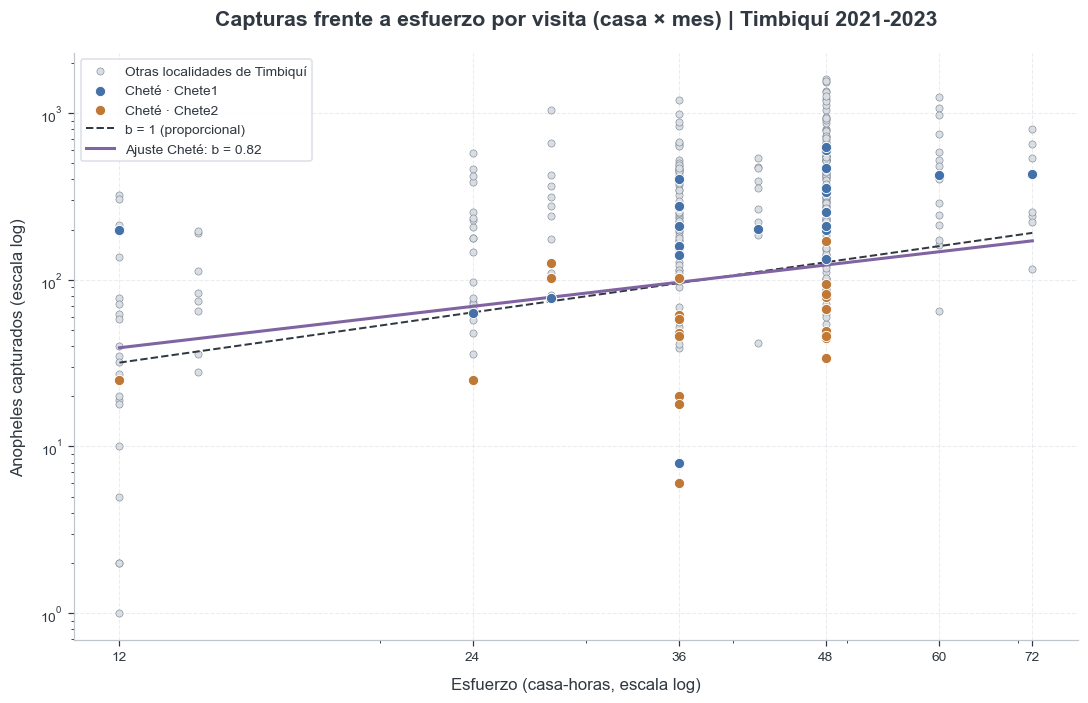

PENDIENTE b (dentro de cada casa) | b = 1 → captura proporcional al esfuerzo


,Grupo,b,IC 95 % inf,IC 95 % sup,Visitas
0,Timbiquí (todas las localidades),1.37,0.92,1.63,349
1,Cheté,0.82,0.43,2.26,44


In [174]:
# ============================================================
# 13.1. CAPTURAS FRENTE A ESFUERZO (LOG-LOG)
# ============================================================
# Modelo: log N = log tasa + b · log E. Si b = 1, la captura es proporcional al esfuerzo.

vis_h1 = visitas[(visitas['county'] == 'Timbiquí') & (visitas['N'] > 0)].copy()
vis_h1['log_N'] = np.log(vis_h1['N'])
vis_h1['log_E'] = np.log(vis_h1['casa_horas'])
es_chete = vis_h1['locality'] == 'Cheté'

def pendiente_dentro_de_casa(d):
    """Pendiente MCO de log N sobre log E tras restar la media de cada casa."""
    x = d['log_E'] - d.groupby('casa')['log_E'].transform('mean')
    y = d['log_N'] - d.groupby('casa')['log_N'].transform('mean')
    return (x * y).sum() / (x ** 2).sum()

def pendiente_bootstrap(d, B=2000, semilla=42):
    """Pendiente con IC 95 % remuestreando meses completos."""
    b = pendiente_dentro_de_casa(d)
    grupos = [g for _, g in d.groupby('campania')]
    rng = np.random.default_rng(semilla)
    boot = []
    for _ in range(B):
        m = pd.concat([grupos[i] for i in rng.integers(0, len(grupos), len(grupos))])
        if m['log_E'].nunique() > 1:
            boot.append(pendiente_dentro_de_casa(m))
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return b, lo, hi, len(d)

res_pend = pd.DataFrame(
    [('Timbiquí (todas las localidades)', *pendiente_bootstrap(vis_h1)),
     ('Cheté', *pendiente_bootstrap(vis_h1[es_chete]))],
    columns=['Grupo', 'b', 'IC 95 % inf', 'IC 95 % sup', 'Visitas']
)

# ------------------------------------------------------------
# Gráfica log-log: las rectas son la forma esperada si N = tasa × E^b
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(vis_h1.loc[~es_chete, 'casa_horas'], vis_h1.loc[~es_chete, 'N'], s=22,
           color=COLORES['gris_claro'], edgecolor=COLORES['gris'], linewidth=0.4,
           label='Otras localidades de Timbiquí', zorder=2)
for casa, color in zip(sorted(vis_h1.loc[es_chete, 'casa'].unique()),
                       [COLORES['principal'], COLORES['secundario']]):
    d = vis_h1[es_chete & (vis_h1['casa'] == casa)]
    ax.scatter(d['casa_horas'], d['N'], s=45, color=color, edgecolor='white',
               linewidth=0.6, label=f'Cheté · {casa}', zorder=4)

# Rectas de referencia que pasan por el centro de Cheté
ch = vis_h1[es_chete]
x0, y0 = ch['log_E'].mean(), ch['log_N'].mean()
xs = np.linspace(vis_h1['log_E'].min(), vis_h1['log_E'].max(), 50)
b_ch = res_pend.loc[1, 'b']
ax.plot(np.exp(xs), np.exp(y0 + 1.0 * (xs - x0)), color=COLORES['texto'],
        linestyle='--', linewidth=1.3, label='b = 1 (proporcional)', zorder=3)
ax.plot(np.exp(xs), np.exp(y0 + b_ch * (xs - x0)), color=COLORES['acento'],
        linewidth=2, label=f'Ajuste Cheté: b = {b_ch:.2f}', zorder=3)

ax.set_xscale('log')
ax.set_yscale('log')
# Marcas legibles en casa-horas reales (1 a 6 noches de 12 h)
ax.set_xticks([12, 24, 36, 48, 60, 72])
ax.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
formato_grafica(
    ax,
    titulo='Capturas frente a esfuerzo por visita (casa × mes) | Timbiquí 2021-2023',
    xlabel='Esfuerzo (casa-horas, escala log)',
    ylabel='Anopheles capturados (escala log)',
    grid_axis='both'
)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print('PENDIENTE b (dentro de cada casa) | b = 1 → captura proporcional al esfuerzo')
display(res_pend.round(2))

### 13.2. Estabilidad de la tasa en Cheté

Si H1 se cumple, la tasa por casa-hora resume la productividad de la casa y es el valor que se multiplica por el esfuerzo.

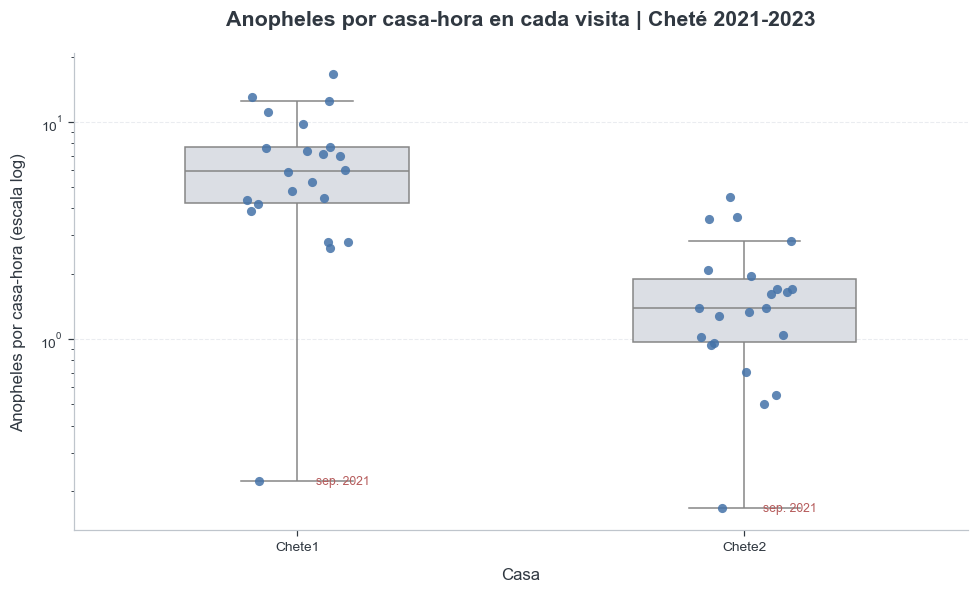

,visitas,individuos,casa_horas,tasa_mediana,tasa_q1,tasa_q3,tasa_global
casa,,,,,,,
Chete1,22,6047,922.0,5.93,4.22,7.64,6.56
Chete2,22,1371,860.0,1.40,0.97,1.90,1.59


Visitas de septiembre de 2021 (posible error de registro):


,casa,inicio,fin,N,noches,horas,tasa
550,Chete1,2021-09-01,2021-09-01,8,3.0,12.0,0.22
572,Chete2,2021-09-03,2021-09-03,6,3.0,12.0,0.17


In [175]:
# ============================================================
# 13.2. DISTRIBUCIÓN DE LA TASA POR CASA EN CHETÉ
# ============================================================
vis_chete = visitas[visitas['locality'] == 'Cheté'].copy()
casas_chete = sorted(vis_chete['casa'].unique())

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=vis_chete, x='casa', y='tasa', order=casas_chete, ax=ax,
            color=COLORES['gris_claro'], fliersize=0, width=0.5)
sns.stripplot(data=vis_chete, x='casa', y='tasa', order=casas_chete, ax=ax,
              color=COLORES['principal'], size=6, jitter=0.12, alpha=0.85)

# Señalar la campaña atípica de septiembre de 2021
atipicas = vis_chete[vis_chete['campania'] == pd.Period('2021-09', freq='M')]
for _, r in atipicas.iterrows():
    ax.annotate('sep. 2021', (casas_chete.index(r['casa']), r['tasa']),
                textcoords='offset points', xytext=(12, 0), fontsize=8,
                color=COLORES['negativo'], va='center')

ax.set_yscale('log')   # la tasa abarca varios órdenes de magnitud (sección 8)
formato_grafica(ax, titulo='Anopheles por casa-hora en cada visita | Cheté 2021-2023',
                xlabel='Casa', ylabel='Anopheles por casa-hora (escala log)')
plt.tight_layout()
plt.show()

resumen_chete = (
    vis_chete.groupby('casa')
    .agg(visitas=('tasa', 'size'),
         individuos=('N', 'sum'),
         casa_horas=('casa_horas', 'sum'),
         tasa_mediana=('tasa', 'median'),
         tasa_q1=('tasa', lambda s: s.quantile(.25)),
         tasa_q3=('tasa', lambda s: s.quantile(.75)))
)
resumen_chete['tasa_global'] = resumen_chete['individuos'] / resumen_chete['casa_horas']
display(resumen_chete.round(2))

print('Visitas de septiembre de 2021 (posible error de registro):')
display(atipicas[['casa', 'inicio', 'fin', 'N', 'noches', 'horas', 'tasa']].round(2))

### 13.3. Predicción para 4 noches en Cheté y comparación con Fermi

Se aplica H1 a cada una de las campañas mensuales observadas en Cheté: $\hat N = \text{tasa del mes} \times \text{esfuerzo}$. La dispersión de esos valores es la **incertidumbre de predicción** (qué tanto puede variar una campaña nueva). Además, el IC de la mediana por bootstrap de meses indica qué tan bien conocemos el valor típico.

| Diseño | Esfuerzo | Supuesto |
|---|---|---|
| **Protocolo histórico** | 2 casas × 4 noches × 12 h = 96 casa-horas | Es como se muestreó Cheté; usa la tasa de cada casa |
| **Diseño de Fermi** | 5 colectores × 4 noches × 5 h = 100 colector-horas | Supone que un colector-hora rinde lo mismo que una casa-hora y que los colectores exteriores capturan igual que los interiores. **No se puede verificar con estos datos** |

La comparación más justa con Fermi es por **tasa horaria**: Fermi supuso 346 *Anopheles* / (5 colectores × 20 h) ≈ 3,5 por colector-hora.

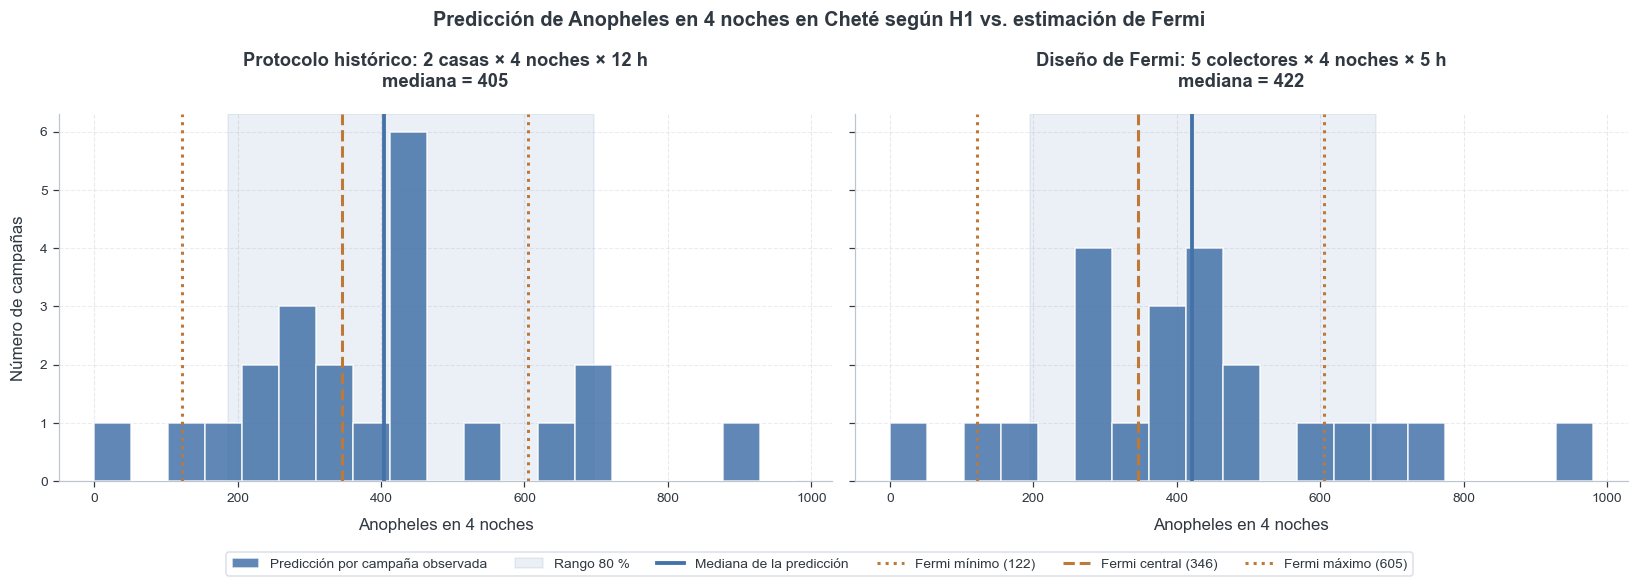

,Mediana,IC 95 % mediana,Rango 80 % (P10–P90),Rango 95 % (P2.5–P97.5),Campañas
Protocolo histórico (2 casas × 12 h),405,286 – 434,187 – 697,89 – 804,22
Diseño de Fermi (5 colectores × 5 h),422,308 – 466,195 – 677,82 – 837,22


COMPARACIÓN POR TASA HORARIA
------------------------------------------------------------
Fermi (caso central):        3.46 Anopheles por colector-hora
Cheté (mediana por campaña): 4.22 Anopheles por casa-hora
Cheté (global Σ N / Σ E):    4.16 Anopheles por casa-hora
------------------------------------------------------------

Visitas reales de 4 noches en Cheté: 19 | rango 80 % esperado por casa: 37 – 438 | dentro del rango: 79%


In [176]:
# ============================================================
# 13.3. PREDICCIÓN PARA 4 NOCHES EN CHETÉ
# ============================================================
NOCHES = 4
FERMI = {'Mínimo': 122, 'Central': 346, 'Máximo': 605}
FERMI_TASA = 346 / (5 * 5 * NOCHES)   # Anopheles por colector-hora en el caso central

# Tasa de cada casa en cada mes (una fila por mes, una columna por casa)
tasas_mes = vis_chete.pivot_table(index='campania', columns='casa', values='tasa')
tasa_campania = (vis_chete.groupby('campania')['N'].sum()
                 / vis_chete.groupby('campania')['casa_horas'].sum())

# Protocolo histórico: cada casa 4 noches × 12 h. Si en un mes falta una casa,
# se usa la tasa de la otra para ambas.
pred_hist = tasas_mes.apply(lambda r: r.fillna(r.mean()).sum(), axis=1) * NOCHES * 12
# Diseño de Fermi: 100 colector-horas a la tasa de la campaña de ese mes
pred_fermi = tasa_campania * (5 * NOCHES * 5)

def resumir(pred, B=5000, semilla=42):
    rng = np.random.default_rng(semilla)
    medianas = [np.median(rng.choice(pred.values, len(pred))) for _ in range(B)]
    return {
        'Mediana': f"{np.median(pred):.0f}",
        'IC 95 % mediana': f"{np.percentile(medianas, 2.5):.0f} – {np.percentile(medianas, 97.5):.0f}",
        'Rango 80 % (P10–P90)': f"{pred.quantile(.10):.0f} – {pred.quantile(.90):.0f}",
        'Rango 95 % (P2.5–P97.5)': f"{pred.quantile(.025):.0f} – {pred.quantile(.975):.0f}",
        'Campañas': len(pred),
    }

tabla_pred = pd.DataFrame({
    'Protocolo histórico (2 casas × 12 h)': resumir(pred_hist),
    'Diseño de Fermi (5 colectores × 5 h)': resumir(pred_fermi),
}).T

# ------------------------------------------------------------
# Gráfica: distribución de las predicciones y escenarios de Fermi
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (nombre, pred) in zip(axes, [('Protocolo histórico: 2 casas × 4 noches × 12 h', pred_hist),
                                     ('Diseño de Fermi: 5 colectores × 4 noches × 5 h', pred_fermi)]):
    ax.hist(pred, bins=np.linspace(0, max(pred_hist.max(), pred_fermi.max(), 650) * 1.05, 20),
            color=COLORES['principal'], edgecolor='white', alpha=0.85, zorder=3,
            label='Predicción por campaña observada')
    ax.axvspan(pred.quantile(.10), pred.quantile(.90), color=COLORES['principal'],
               alpha=0.10, zorder=1, label='Rango 80 %')
    ax.axvline(pred.median(), color=COLORES['principal'], linewidth=2.5,
               label='Mediana de la predicción', zorder=4)
    for (esc, val), estilo in zip(FERMI.items(), [':', '--', ':']):
        ax.axvline(val, color=COLORES['secundario'], linestyle=estilo, linewidth=2,
                   label=f'Fermi {esc.lower()} ({val})', zorder=4)
    formato_grafica(ax, titulo=f'{nombre}\nmediana = {pred.median():.0f}',
                    xlabel='Anopheles en 4 noches',
                    ylabel='Número de campañas' if ax is axes[0] else None)
    ax.title.set_fontsize(12)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.06), fontsize=9)
fig.suptitle('Predicción de Anopheles en 4 noches en Cheté según H1 vs. estimación de Fermi',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

display(tabla_pred)

print('COMPARACIÓN POR TASA HORARIA')
print('-' * 60)
print(f"Fermi (caso central):        {FERMI_TASA:.2f} Anopheles por colector-hora")
print(f"Cheté (mediana por campaña): {tasa_campania.median():.2f} Anopheles por casa-hora")
print(f"Cheté (global Σ N / Σ E):    {vis_chete['N'].sum() / vis_chete['casa_horas'].sum():.2f} Anopheles por casa-hora")
print('-' * 60)

# ------------------------------------------------------------
# Control: ¿las visitas reales de 4 noches caen en el rango esperado por casa?
# (control dentro de la muestra, no una validación independiente)
# ------------------------------------------------------------
reales = vis_chete[vis_chete['noches'] == NOCHES].copy()
pred_casa = vis_chete['tasa'] * NOCHES * reales['horas'].mode()[0]
p10, p90 = pred_casa.quantile([.10, .90])
reales['dentro_80'] = reales['N'].between(p10, p90)
print(f"\nVisitas reales de 4 noches en Cheté: {len(reales)} | "
      f"rango 80 % esperado por casa: {p10:.0f} – {p90:.0f} | "
      f"dentro del rango: {reales['dentro_80'].mean():.0%}")

## 14. Conclusiones

**Pregunta:** ¿cuántos *Anopheles* se podrían capturar en una campaña de cuatro noches en Cheté, y con qué incertidumbre?

1. **Medida de captura.** La unidad válida es la visita (casa × mes) y la medida comparable es *Anopheles* por casa-hora. Los conteos crudos dependen del esfuerzo, que va de 1 a 6 noches de 12 o 14 h. La tasa es muy asimétrica (de 0,03 a 37 por casa-hora), por eso se analiza en escala log.

2. **H1: la captura es proporcional al esfuerzo (sección 13.1).** La pendiente log-log dentro de cada casa es b ≈ 1,37 [0,92; 1,63] en Timbiquí y b ≈ 0,82 [0,43; 2,26] en Cheté. Ambos intervalos incluyen b = 1, así que los datos son **compatibles con la proporcionalidad**, que es el supuesto central del modelo de Fermi (tasa × colectores × horas). En Cheté el intervalo es ancho (44 visitas).

3. **La casa es la mayor fuente de variación (secciones 12 y 13.2).** En Cheté, Chete1 captura unas 4 veces más que Chete2. En las localidades del río Timbiquí cercanas a Cheté pasa lo mismo: Coteje repite el patrón, tiene una diferencia mayor que la de Cheté frente a sus vecinas. Solo Velásquez es indistinguible de Cheté en tasa.

4. **Predicción para 4 noches en Cheté (sección 13.3).**
   - Con el protocolo histórico (2 casas × 12 h), la mediana es de **unos 405 *Anopheles***. El IC 95 % de la mediana va de 286 a 434 y el rango del 80 % para una campaña nueva, de **187 a 697**.
   - Con el diseño de Fermi (5 colectores × 5 h), la mediana es de unos 422 (rango del 80 %: 195–677). Este resultado supone que un colector exterior rinde igual que uno interior.
   - El caso central de Fermi (346) cae dentro del rango esperado, algo por debajo de la mediana. Su tasa implícita (3,5 por colector-hora) es cercana a la observada en Cheté (4,2 por casa-hora).

5. **Lluvia (H2, secciones 9 a 11).** La relación con la tasa de captura es débil y no es significativa.
   - **Por qué hay que normalizar:** con los conteos crudos, la lluvia durante la campaña parece *reducir* las capturas (ρ = −0,32, p = 0,03). Pero el esfuerzo también fue menor en esos meses (ρ = −0,23); al dividir por casa-horas, la relación desaparece. Comparar conteos sin normalizar habría llevado a una conclusión equivocada.
   - La lluvia no mejora de forma apreciable la predicción.

6. **Supuestos de Fermi que no se pueden verificar con estos datos:** captura interior frente a exterior (todos los registros son "En domicilio"), franjas horarias (cada registro cubre 17:00–05:00) y proporción de *Anopheles* $p_a$ (solo se registran *Anopheles*).

**Limitaciones:**
- La campaña de septiembre de 2021 en Cheté tiene tasas atípicamente bajas.
- Las campañas consecutivas pueden estar correlacionadas.
- Solo hay registros cuando hubo capturas, así que no se ven visitas con cero individuos.
- El número de noches no se asignó al azar, lo que puede sesgar el ajuste de la dependencia de la tasa de captura con el esfuerzo.